# Avance 3 · Modelo baseline y desarrollo de modelos
## Proyecto Integrador — Perfiles antioxidantes en fresas · Equipo 54

**Tecnológico de Monterrey**  
**Proyecto:** Comparación y modelación de perfiles antioxidantes para las variedades de fresa *Donna* y *Dream*  
**Integrantes:**

- Fanny Betsabé Fuentes Reyes — A00570705
- Juan Luis Ramírez Sánchez — A01705151
- Joaquín Rincón Pérez — A01797105

### Objetivo del avance

Construir un **modelo de referencia (baseline)** para evaluar la viabilidad predictiva del problema y compararlo con modelos estadísticos y de Machine Learning más complejos, preservando el diseño experimental y la interpretabilidad científica.

La libreta integra tres objetivos en paralelo:

1. **Inferencia:** estudiar efectos de tratamiento, cultivar e interacción.
2. **Integración multivariada:** explorar relaciones suelo → hoja → fruto.
3. **Predicción:** determinar si suelo, hoja, cultivar y tratamiento contienen información suficiente para anticipar resultados de producción y calidad.

> **Navegación.** La libreta está organizada con encabezados Markdown. En JupyterLab los capítulos pueden plegarse/desplegarse desde el triángulo ubicado junto al encabezado.


## Índice

1. Contexto y entendimiento del experimento
2. Hipótesis y metodologías sugeridas
3. Nuevo EDA acotado
4. Transformaciones y preparación para modelado
6. Modelos y algoritmos
7. Comparación de resultados y conclusiones


# 1. Contexto y entendimiento del experimento

## 1.1 Contexto experimental

El estudio evalúa dos cultivares, **Donna** y **Dream**, bajo cuatro sistemas de manejo:

| Código original | Nombre que se mostrará | Manejo |
|---|---|---|
| T1 | **Compost** | Composta orgánica; labranza regular |
| T2 | **N-rich** | Fertilizante orgánico rico en nitrógeno; labranza regular |
| T3 | **RCW-HD** | Restos leñosos de poda municipal, dosis alta; sin labranza después de la incorporación inicial |
| T4 | **RCW-LD** | Restos leñosos de poda municipal, dosis baja; sin labranza después de la incorporación inicial |

### ¿Qué significa *labranza*?

La **labranza** es el trabajo mecánico del suelo mediante herramientas o maquinaria para removerlo, aflojarlo, airearlo, controlar malezas o incorporar materiales. En este experimento es importante porque **Compost y N-rich incluyen labranza regular, mientras que RCW-HD y RCW-LD no** después de la incorporación inicial.

Por ello, `Treatment` debe interpretarse como un **sistema de manejo completo** y no exclusivamente como el material aplicado. Si aparecen diferencias entre Compost y RCW-HD, con estos datos no siempre será posible atribuirlas únicamente al tipo de enmienda, porque también cambia la práctica de labranza.

## 1.2 Lógica causal de trabajo

La estructura conceptual que queremos estudiar es:

**Tratamiento → propiedades del suelo → respuesta de la planta → producción y calidad del fruto**

El cultivar puede modificar esta respuesta, por lo que también estudiaremos **Treatment × Cultivar**.


In [2]:
# Librerías y configuración general
from pathlib import Path
import re, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.stats import spearmanr, skew, shapiro, levene, f_oneway, kruskal
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', 140)
pd.set_option('display.width', 190)
sns.set_theme(style='whitegrid', palette='deep')

SEED = 54
np.random.seed(SEED)

BASE_DIR = Path.cwd().resolve()
OUT = BASE_DIR / 'outputs' / 'avance3_modelado'
FIG = OUT / 'figuras'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
    'antiox': 'Antiox_data.xlsx',
    'sampling': 'Sampling May 2023.xlsx',
    'harvests': 'harvests.xlsx',
    'soil': 'Dataset_final_suelo.xlsx',
    'leaf': 'Dataset_final_leaf.xlsx',
    'poly_raw': 'alldata_polyphenols.xlsx',
    'anth_raw': 'Anthocyanins.xlsx',
    'vitc_raw': 'VitC_MarinaPerez.xlsx',
    'poly_table': 'Table polyphenols.xlsx',
}

missing_files = [name for name in FILES.values() if not (BASE_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        'Faltan archivos Excel en la misma carpeta del notebook: ' + ', '.join(missing_files)
    )

print('Directorio de trabajo:', BASE_DIR)
print('Archivos requeridos detectados:', len(FILES))
print('Resultados:', OUT)

Directorio de trabajo: C:\Users\joaqu\OneDrive\Documentos\02. Maestría Tec\8° Trimestre\Proyecto Integrador
Archivos requeridos detectados: 9
Resultados: C:\Users\joaqu\OneDrive\Documentos\02. Maestría Tec\8° Trimestre\Proyecto Integrador\outputs\avance3_modelado


## 1.3 Reconstrucción de las fuentes y unidad analítica

Se reutiliza la lógica de integración desarrollada en los avances anteriores. La unidad maestra será:

> **Cultivar × Tratamiento × Réplica**

Con dos cultivares, cuatro tratamientos y cuatro réplicas se esperan **32 observaciones analíticas**.

También se construye `Parcel_ID = Treatment × Replicate` para representar las **16 parcelas**. 
Esto se realiza porque Donna y Dream pueden compartir información de suelo dentro de la misma parcela.


In [8]:
SHEETS = {
    'antiox': {'Antiox_data': None},
    'sampling': {'all_data': None},
    'harvests': {'harvests': None, 'productions_kg': None},
    'soil': {'Final': None},
    'leaf': {'Isotopes': None, 'RGB': None, 'Nitrates': None, 'Nutrients': 1},
    'poly_raw': {'alldata_polyphenols': None, 'data_polyphenols': None},
    'anth_raw': {'Cyanidin gluc': None, 'Pelargonidin gluc': None, 'Pelargonidin rutin': None},
    'vitc_raw': {'Hoja3': None},
}

inventory=[]
for key, name in FILES.items():
    book = pd.ExcelFile(BASE_DIR / name)
    for sheet in book.sheet_names:
        inventory.append({'Fuente':key,'Archivo':name,'Hoja':sheet})
    if key in SHEETS:
        for sheet in SHEETS[key]:
            if sheet not in book.sheet_names:
                raise ValueError(f'{name}: falta hoja {sheet!r}. Hojas disponibles: {book.sheet_names}')

inventory_df = pd.DataFrame(inventory)
raw={}
for key, sheets in SHEETS.items():
    for sheet, header in sheets.items():
        args={'sheet_name':sheet}
        if header is not None:
            args['header']=header
        df=pd.read_excel(BASE_DIR / FILES[key], **args)
        df.columns=[str(c).strip() for c in df.columns]
        raw[(key,sheet)] = df
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Filas']=len(df)
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Columnas']=df.shape[1]

display(inventory_df.loc[inventory_df['Filas'].notna(), ['Fuente','Archivo','Hoja','Filas','Columnas']])


,Fuente,Archivo,Hoja,Filas,Columnas
0,antiox,Antiox_data.xlsx,Antiox_data,32.0,27.0
8,sampling,Sampling May 2023.xlsx,all_data,32.0,19.0
10,harvests,harvests.xlsx,harvests,608.0,13.0
12,harvests,harvests.xlsx,productions_kg,32.0,18.0
16,soil,Dataset_final_suelo.xlsx,Final,32.0,15.0
18,leaf,Dataset_final_leaf.xlsx,Nitrates,65.0,14.0
19,leaf,Dataset_final_leaf.xlsx,Isotopes,64.0,9.0
20,leaf,Dataset_final_leaf.xlsx,RGB,96.0,8.0
21,leaf,Dataset_final_leaf.xlsx,Nutrients,64.0,28.0
22,poly_raw,alldata_polyphenols.xlsx,alldata_polyphenols,64.0,20.0


In [10]:
antiox_raw = raw[('antiox','Antiox_data')]
fruit_raw = raw[('sampling','all_data')]
harvest_raw = raw[('harvests','harvests')]
yield_raw = raw[('harvests','productions_kg')]
soil_raw = raw[('soil','Final')]
iso_raw = raw[('leaf','Isotopes')]
rgb_raw = raw[('leaf','RGB')]
nitr_raw = raw[('leaf','Nitrates')]
nut_raw = raw[('leaf','Nutrients')].copy()
nut_raw = nut_raw.loc[:, ~nut_raw.columns.astype(str).str.startswith('Unnamed')]
nitr_raw = nitr_raw.loc[nitr_raw['Parcel/Plot'].notna()].copy()

CORE = {
    'Antioxidantes':antiox_raw, 'Calidad fruto':fruit_raw, 'Producción':yield_raw,
    'Cosechas por fecha':harvest_raw, 'Suelo':soil_raw, 'Hoja isótopos':iso_raw,
    'Hoja nitratos':nitr_raw, 'Hoja nutrientes':nut_raw, 'Hoja RGB':rgb_raw
}

def describe_source(name, df):
    return {
        'Fuente':name, 'Filas':len(df), 'Columnas':df.shape[1],
        'Numéricas':df.select_dtypes(include=np.number).shape[1],
        'NA totales':int(df.isna().sum().sum()),
        'Filas idénticas':int(df.duplicated().sum())
    }

source_profile = pd.DataFrame([describe_source(k,d) for k,d in CORE.items()])
display(source_profile)


,Fuente,Filas,Columnas,Numéricas,NA totales,Filas idénticas
0,Antioxidantes,32,27,22,12,0
1,Calidad fruto,32,19,16,14,0
2,Producción,32,18,12,99,0
3,Cosechas por fecha,608,13,8,912,0
4,Suelo,32,15,13,0,0
5,Hoja isótopos,64,9,4,0,0
6,Hoja nitratos,64,14,9,0,0
7,Hoja nutrientes,64,24,20,0,0
8,Hoja RGB,96,8,4,0,0


In [12]:
# Estandarización de tratamientos.
SOIL_TO_T = {
    'COMPOST':'T1', 'N-RICH':'T2', 'NRICH':'T2',
    'RCW-HD':'T3','RWC-HD':'T3','WR-HD':'T3','RCWHD':'T3',
    'RCW-LD':'T4','RWC-LD':'T4','WR-LD':'T4','RCWLD':'T4'
}
# IMPORTANTE: en todos los gráficos/tablas visibles se usarán nombres, no códigos.
T_TO_NAME = {'T1':'Compost', 'T2':'N-rich', 'T3':'RCW-HD', 'T4':'RCW-LD'}
TREATMENT_ORDER = ['Compost','N-rich','RCW-HD','RCW-LD']

def clean_cv(s):
    v=s.astype('string').str.strip().str.upper()
    return v.map({'DO':'Donna','DONA':'Donna','DONNA':'Donna','DR':'Dream','DREAM':'Dream'})

def clean_code(s):
    return s.astype('string').str.strip().str.upper().str.replace(r'\s+','',regex=True)

def require_cols(df, cols, label):
    missing=set(cols)-set(df.columns)
    if missing:
        raise KeyError(f'{label}: columnas no encontradas: {sorted(missing)}; disponibles={list(df.columns)}')

KEYS=['Cultivar','Treatment','Replicate']

def make_keys(df, cv, tr, rep, label):
    require_cols(df,[cv,tr,rep],label)
    return pd.DataFrame({
        'Cultivar':clean_cv(df[cv]),
        'Treatment':clean_code(df[tr]),
        'Replicate':clean_code(df[rep])
    }, index=df.index)

def check_unique(df, keys, label):
    na=df[keys].isna().any(axis=1)
    dup=df.duplicated(keys,keep=False)
    if na.any() or dup.any():
        display(df.loc[na|dup,keys].head(20))
        raise ValueError(f'{label}: claves nulas o duplicadas; no se realizará unión insegura.')

display(pd.DataFrame([{'Código original':k,'Tratamiento mostrado':v} for k,v in T_TO_NAME.items()]))


,Código original,Tratamiento mostrado
0,T1,Compost
1,T2,N-rich
2,T3,RCW-HD
3,T4,RCW-LD


In [13]:
# Construcción de las fuentes principales en Cultivar × Treatment × Replicate.
ant = make_keys(antiox_raw,'cultivar','Treatment','Replicate','Antiox_data')
for c in antiox_raw.columns:
    if c not in ['Sample','cultivar','Treatment','Replicate','New_block']:
        ant[c]=pd.to_numeric(antiox_raw[c],errors='coerce')
check_unique(ant,KEYS,'Antioxidantes')

fruit = make_keys(fruit_raw,'Cv','Treatment','Repl','Sampling/all_data')
for c in ['Weight','Hydrat','Firm','Hue','Chroma','BRIX','Acidity','GA','GGA','CSI']:
    if c in fruit_raw:
        fruit['fruit_'+c]=pd.to_numeric(fruit_raw[c],errors='coerce')
check_unique(fruit,KEYS,'Calidad del fruto')

yld = make_keys(yield_raw,'Cv','Treatment','Repl','Producción')
for c in ['Com Ton/ha','No com Ton/ha','Nº de plantes','g/planta']:
    if c in yield_raw:
        yld['yield_'+c]=pd.to_numeric(yield_raw[c],errors='coerce')
check_unique(yld,KEYS,'Producción')

sets_keys={name:set(map(tuple,df[KEYS].to_numpy())) for name,df in {'Antiox':ant,'Fruto':fruit,'Producción':yld}.items()}
assert sets_keys['Antiox']==sets_keys['Fruto']==sets_keys['Producción'], 'Las claves de las fuentes principales no coinciden.'

# Suelo 2023: una observación por Treatment × Replicate.
require_cols(soil_raw,['Treatment','Block','Year'],'Suelo/Final')
soil23=soil_raw.loc[pd.to_numeric(soil_raw['Year'],errors='coerce').eq(2023)].copy()
soil_t_raw=clean_code(soil23['Treatment']).str.replace('_','-',regex=False)
soil=pd.DataFrame({'Treatment':soil_t_raw.map(SOIL_TO_T), 'Replicate':clean_code(soil23['Block'])}, index=soil23.index)
for c in soil23.columns:
    if c not in ['Treatment','Year','Block','Plot']:
        soil['soil_'+c]=pd.to_numeric(soil23[c],errors='coerce')
if soil.Treatment.isna().any():
    raise ValueError('Existen tratamientos de suelo sin mapear: '+str(soil23.loc[soil.Treatment.isna(),'Treatment'].unique()))
check_unique(soil,['Treatment','Replicate'],'Suelo 2023')

# Hojas: réplicas técnicas en la misma unidad/fecha se resumen por media.
def pivot_leaf(df,cv,tr,rep,time,measures,prefix,label):
    require_cols(df,[cv,tr,rep]+measures,label)
    k=make_keys(df,cv,tr,rep,label)
    k['Time']=pd.Series(time,index=df.index).astype('string').str.strip()
    for c in measures:
        k[c]=pd.to_numeric(df[c],errors='coerce')
    piv=k.pivot_table(index=KEYS, columns='Time', values=measures, aggfunc='mean')
    piv.columns=[f'{prefix}_{str(c)}_{str(t)}' for c,t in piv.columns]
    return piv.reset_index()

iso_t=iso_raw['Date'].astype('string').str.extract('(March|May)',expand=False)
leaf_iso=pivot_leaf(iso_raw,'Cv','Treatment','Replicate',iso_t,
                    [c for c in ['%N','d13C'] if c in iso_raw], 'leaf_iso','Isotopes')

nut_vars=[c for c in nut_raw.columns if c not in ['Sample','Parcel/Plot','Cv','Treatment','Repl','Time']
          and pd.api.types.is_numeric_dtype(nut_raw[c])]
leaf_nut=pivot_leaf(nut_raw,'Cv','Treatment','Repl',nut_raw['Time'],nut_vars,'leaf_nut','Nutrients')
leaf_no3=pivot_leaf(nitr_raw,'Cv','Treatment','Repl',nitr_raw['Time'],
                    [c for c in ['mg NO3-/ g DW','mg NO3-/ 100 mg DW'] if c in nitr_raw],
                    'leaf_no3','Nitrates')
leaf_rgb=pivot_leaf(rgb_raw,'Cv','Treatment','Repl',rgb_raw['Time'],
                    [c for c in ['GA','GGA','CSI'] if c in rgb_raw], 'leaf_rgb','RGB')

# Unión maestra.
ana=ant.merge(fruit,on=KEYS,how='outer',validate='one_to_one',indicator='_source_fruit')
ana=ana.merge(yld,on=KEYS,how='outer',validate='one_to_one',indicator='_source_yield')
ana=ana.merge(soil,on=['Treatment','Replicate'],how='left',validate='many_to_one',indicator='_source_soil')
for x in [leaf_iso,leaf_nut,leaf_no3,leaf_rgb]:
    ana=ana.merge(x,on=KEYS,how='left',validate='one_to_one')

ana['Parcel_ID']=ana['Treatment'].astype(str)+'_'+ana['Replicate'].astype(str)
ana['Treatment_name']=ana['Treatment'].map(T_TO_NAME).fillna('Sin mapear')
ana['Cultivar_Treatment']=ana['Cultivar'].astype(str)+' · '+ana['Treatment_name'].astype(str)

assert not ana[KEYS].duplicated().any(), 'La unión generó llaves duplicadas.'
print('Filas analíticas:',len(ana))
print('Parcelas:',ana.Parcel_ID.nunique())
print('Variables numéricas:',len(ana.select_dtypes(include=np.number).columns))
print('Tratamientos visibles:',sorted(ana.Treatment_name.unique()))

if len(ana)!=32 or ana.Parcel_ID.nunique()!=16:
    warnings.warn('Cobertura distinta de 32 filas / 16 parcelas: revisar fuentes y llaves de unión.')


Filas analíticas: 32
Parcelas: 16
Variables numéricas: 100
Tratamientos visibles: ['Compost', 'N-rich', 'RCW-HD', 'RCW-LD']


In [14]:
# Bloques científicos.
design_cols=['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment']
soil_cols=[c for c in ana if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana[c])]
leaf_nutrition_cols=[c for c in ana if c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) and pd.api.types.is_numeric_dtype(ana[c])]
rgb_cols=[c for c in ana if c.startswith('leaf_rgb_') and pd.api.types.is_numeric_dtype(ana[c])]
production_cols=[c for c in ana if c.startswith('yield_') and pd.api.types.is_numeric_dtype(ana[c])]
rgb_duplicate_outcomes=[c for c in ['fruit_GA','fruit_GGA','fruit_CSI'] if c in ana.columns]
# GA/GGA/CSI del archivo de sampling se consideran indicadores de vegetación/RGB, no calidad fisicoquímica del fruto.
# Además, en el EDA previo se observó que duplican las mediciones RGB de mayo; se excluyen de outcomes para evitar relaciones innecesarias.
physchem_cols=[c for c in ana if c.startswith('fruit_') and pd.api.types.is_numeric_dtype(ana[c]) and c not in rgb_duplicate_outcomes]
nutritional_cols=[c for c in ant.columns if c not in KEYS and c in ana.columns and pd.api.types.is_numeric_dtype(ana[c])]

BLOCKS={
    'Diseño experimental':design_cols,
    'Suelo':soil_cols,
    'Hoja / nutrición':leaf_nutrition_cols,
    'Hoja / RGB-fisiología':rgb_cols,
    'Producción':production_cols,
    'Calidad fisicoquímica':physchem_cols,
    'Calidad nutricional / bioactivos':nutritional_cols,
}
block_summary=pd.DataFrame([{'Bloque':k,'Variables':len(v)} for k,v in BLOCKS.items()])
display(block_summary)

X_raw_cols=soil_cols+leaf_nutrition_cols+rgb_cols
outcome_families={
    'Producción':production_cols,
    'Fisicoquímica':physchem_cols,
    'Nutricional':nutritional_cols,
}

advantages = [
    'Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.',
    'Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.',
    'Mediciones temporales en suelo y hoja que permiten estudiar evolución.',
    'Resultados químicos y bioactivos suficientes para formular objetivos múltiples.'
]
limitations = [
    'n≈32 es pequeño frente al número de variables (p >> n).',
    'Algunas variables presentan faltantes y distribuciones sesgadas.',
    'Suelo se comparte por parcela; no todas las columnas son observaciones independientes.',
    'Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.',
    'Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.'
]

display(Markdown('### Ventajas de la información\n' + '\n'.join([f'- {x}' for x in advantages])))
display(Markdown('### Limitaciones que condicionan el modelado\n' + '\n'.join([f'- {x}' for x in limitations])))

print('Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia:', rgb_duplicate_outcomes)


,Bloque,Variables
0,Diseño experimental,6
1,Suelo,11
2,Hoja / nutrición,44
3,Hoja / RGB-fisiología,9
4,Producción,4
5,Calidad fisicoquímica,7
6,Calidad nutricional / bioactivos,22


### Ventajas de la información
- Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.
- Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.
- Mediciones temporales en suelo y hoja que permiten estudiar evolución.
- Resultados químicos y bioactivos suficientes para formular objetivos múltiples.

### Limitaciones que condicionan el modelado
- n≈32 es pequeño frente al número de variables (p >> n).
- Algunas variables presentan faltantes y distribuciones sesgadas.
- Suelo se comparte por parcela; no todas las columnas son observaciones independientes.
- Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.
- Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.

Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia: ['fruit_GA', 'fruit_GGA', 'fruit_CSI']


# 2. Hipótesis y metodologías sugeridas

## 2.1 ¿Qué se quiere investigador específicamente?

1. Comparar **Compost, N-rich, RCW-HD y RCW-LD**.
2. Comparar **Donna y Dream**.
3. Evaluar **Treatment × Cultivar**: un tratamiento puede funcionar de manera diferente según el cultivar.
4. Entender la relación **suelo → hoja → fruto**.
5. Dar especial atención a **nutrición mineral de la planta → calidad del fruto**.
6. Explorar indicadores **RGB** como señales complementarias de estado fisiológico/estrés.
7. Considerar `δ13C` como indicador fisiológico potencial, sin asumir que necesariamente discriminará bien bajo las condiciones del ensayo.
8. Integrar producción, calidad fisicoquímica, vitamina C, antioxidantes, polifenoles y antocianinas.

## 2.2 Hipótesis de trabajo

| Hipótesis | Pregunta | Método principal |
|---|---|---|
| H1 | ¿Cambian los resultados entre tratamientos? | ANOVA de dos vías + LMM |
| H2 | ¿Donna y Dream responden distinto? | ANOVA/LMM + interacción |
| H3 | ¿Treatment × Cultivar importa? | Interacción factorial |
| H4 | ¿Suelo y hoja se relacionan con calidad del fruto? | Spearman + FDR, PLS, regresión |
| H5 | ¿La evolución temporal aporta información? | Baseline + delta; tendencias temporales |
| H6 | ¿Existen patrones multivariados? | PCA, RDA exploratoria, clustering |
| H7 | ¿Los datos permiten predecir outcomes mejor que una regla ingenua? | DummyRegressor → Ridge → PLS/ElasticNet/PCA+Ridge/RF |

## 2.3 Por qué estos algoritmos

- **DummyRegressor:** referencia mínima; predice la media del entrenamiento y cuantifica cuánto valor agrega realmente un modelo.
- **Ridge Regression:** baseline aprendido principal. Es interpretable, regulariza y funciona bien con muchas variables correlacionadas.
- **Elastic Net:** combina L1 y L2; puede reducir coeficientes irrelevantes y funciona como selección *embedded*.
- **PLS Regression:** particularmente apropiado cuando hay pocas observaciones, muchas variables y alta colinealidad; construye componentes orientados a explicar `Y`.
- **PCA + Ridge:** separa reducción de dimensionalidad y predicción; permite comparar componentes no supervisados contra PLS.
- **Random Forest:** incorpora relaciones no lineales e interacciones sin especificarlas manualmente; se usa de forma conservadora por el tamaño de muestra.
- **ANOVA / LMM:** no son modelos predictivos de ML, pero son esenciales para responder la pregunta experimental y respetar bloques/réplicas.
- **RDA exploratoria:** permite integrar bloques y visualizar variación multivariada asociada con tratamiento/cultivar.

### Métodos que deliberadamente NO priorizamos

No se utilizarán redes neuronales ni ensambles de alta complejidad como primera opción. Con ~32 observaciones, su flexibilidad incrementaría el riesgo de sobreajuste y dificultaría la interpretación.


<p align="center">
  <img src="../outputs/figures/flujo_baseline_modelos.png" width="1400">
</p>

<p align="center">
  <em>Figura. Flujo de trabajo para la construcción del baseline, comparación de modelos y validación de resultados.</em>
</p>

# 3. EDA acotado

In [16]:
# 3.1 Cobertura y faltantes por bloque.
summary_rows=[]
for block, cols in BLOCKS.items():
    numeric=[c for c in cols if c in ana.columns and pd.api.types.is_numeric_dtype(ana[c])]
    if numeric:
        miss=int(ana[numeric].isna().sum().sum())
        total=len(ana)*len(numeric)
        summary_rows.append({'Bloque':block,'Variables numéricas':len(numeric),'Celdas NA':miss,'% NA':100*miss/total})
block_missing=pd.DataFrame(summary_rows)
display(block_missing.round(2))

missing_by_var=(ana.isna().sum().sort_values(ascending=False).rename('NA').to_frame())
missing_by_var['%']=100*missing_by_var['NA']/len(ana)
display(missing_by_var.query('NA > 0').head(20).round(2))


,Bloque,Variables numéricas,Celdas NA,% NA
0,Suelo,11,0,0.00
1,Hoja / nutrición,44,0,0.00
2,Hoja / RGB-fisiología,9,0,0.00
3,Producción,4,0,0.00
4,Calidad fisicoquímica,7,2,0.89
5,Calidad nutricional / bioactivos,22,12,1.70


,NA,%
Tot anth,3,9.38
Cyan,3,9.38
P rut,3,9.38
P gluc,3,9.38
fruit_Hue,1,3.12
fruit_Chroma,1,3.12


## 3.2 Visualización con Seaborn

Se utilizarán **boxplots + observaciones individuales**. El boxplot resume la distribución y los puntos permiten conservar la visibilidad de las réplicas, algo especialmente importante con una muestra pequeña.


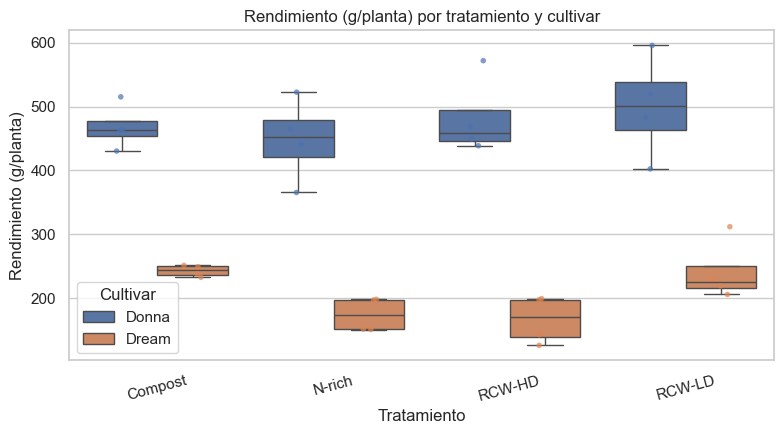

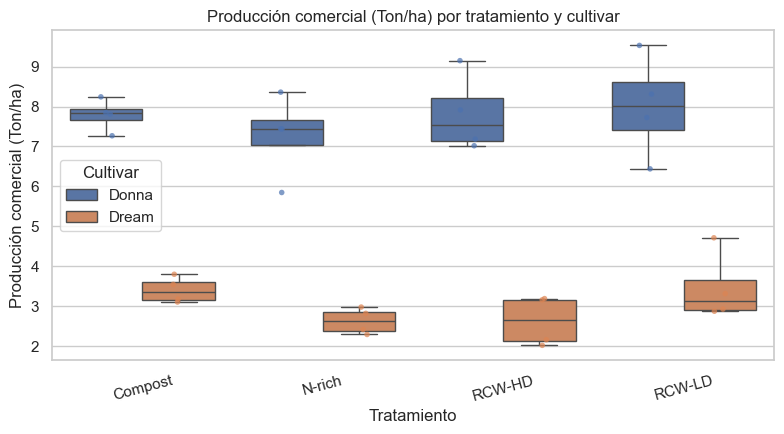

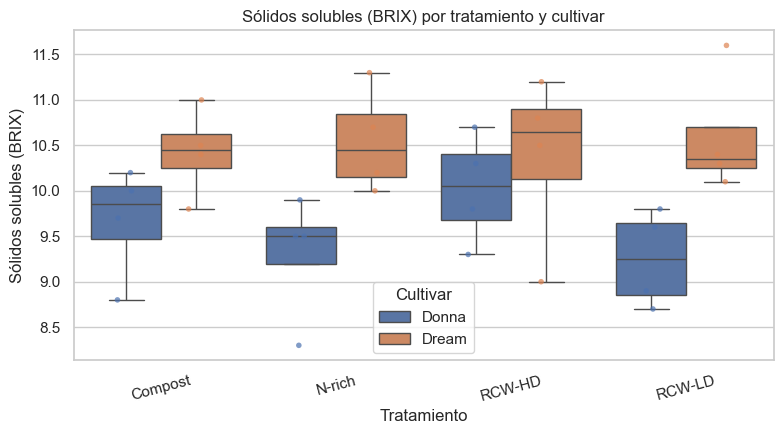

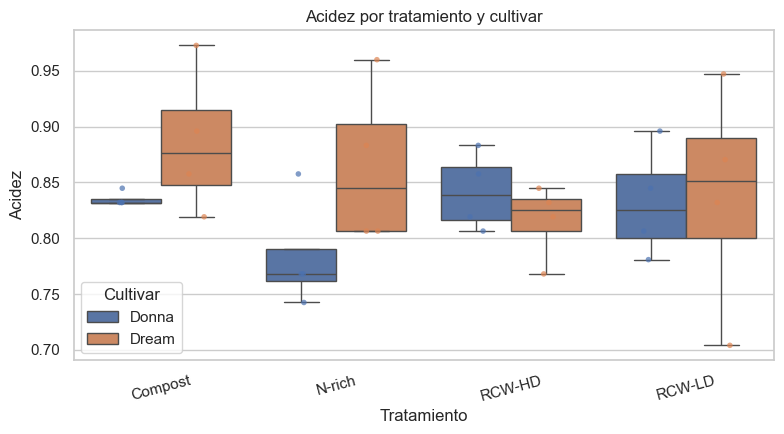

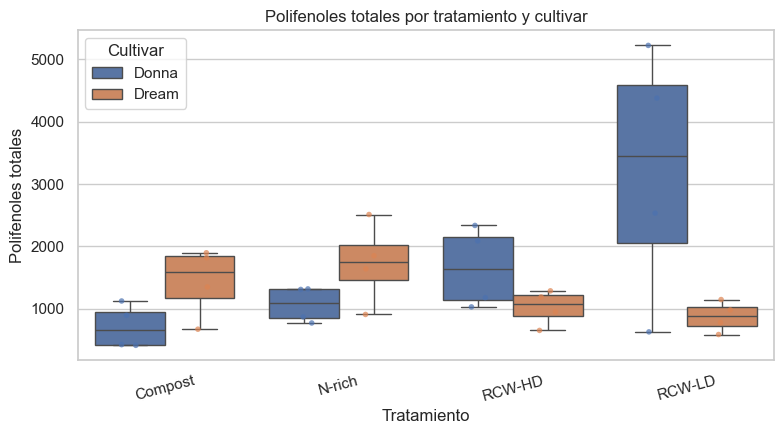

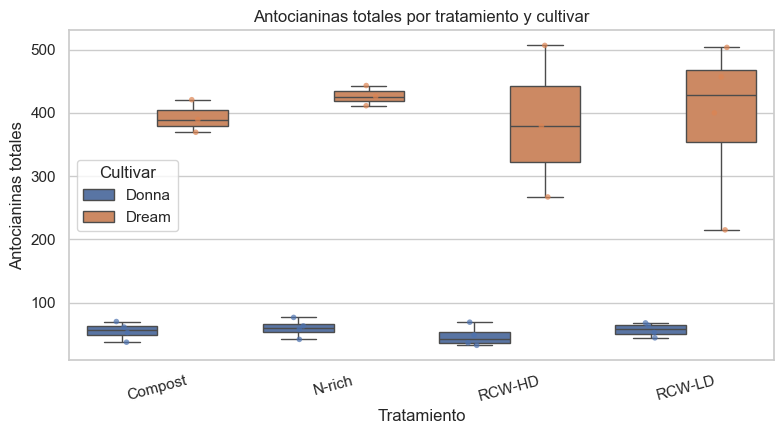

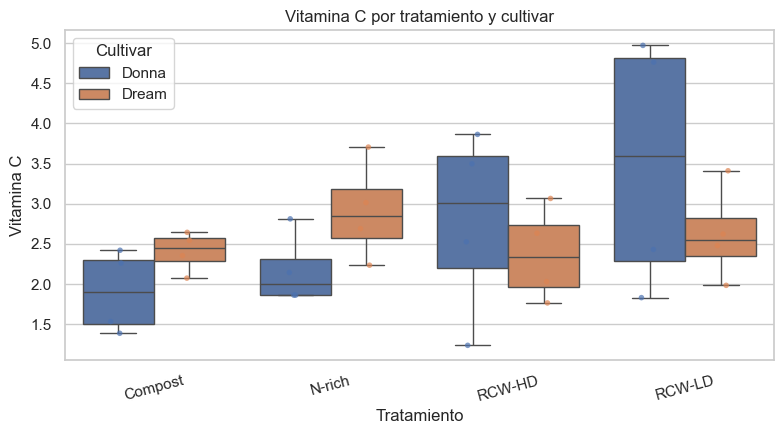

In [17]:
# Variables representativas de las tres familias de resultados.
EDA_TARGETS = [
    ('yield_g/planta','Rendimiento (g/planta)'),
    ('yield_Com Ton/ha','Producción comercial (Ton/ha)'),
    ('fruit_BRIX','Sólidos solubles (BRIX)'),
    ('fruit_Acidity','Acidez'),
    ('Total polyphenols','Polifenoles totales'),
    ('Tot anth','Antocianinas totales'),
    ('Vit C','Vitamina C'),
]

for col, label in EDA_TARGETS:
    if col not in ana.columns:
        continue
    d=ana[['Treatment_name','Cultivar',col]].dropna()
    fig, ax=plt.subplots(figsize=(8,4.5))
    sns.boxplot(data=d,x='Treatment_name',y=col,hue='Cultivar',order=TREATMENT_ORDER,showfliers=False,ax=ax)
    sns.stripplot(data=d,x='Treatment_name',y=col,hue='Cultivar',order=TREATMENT_ORDER,
                  dodge=True,alpha=.7,size=4,legend=False,ax=ax)
    ax.set_title(f'{label} por tratamiento y cultivar')
    ax.set_xlabel('Tratamiento'); ax.set_ylabel(label)
    plt.xticks(rotation=15)
    plt.tight_layout(); plt.show()


## 3.3 Alternativa equivalente con Matplotlib

Para demostrar que la lectura no depende de una librería de alto nivel, se presenta la misma lógica mediante medias y error estándar usando Matplotlib.


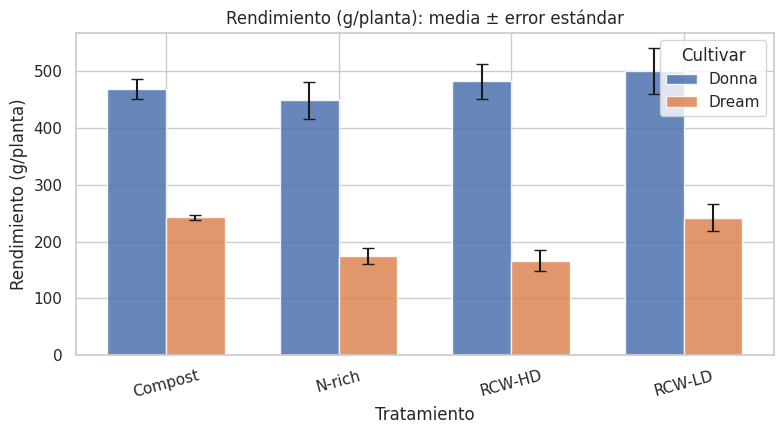

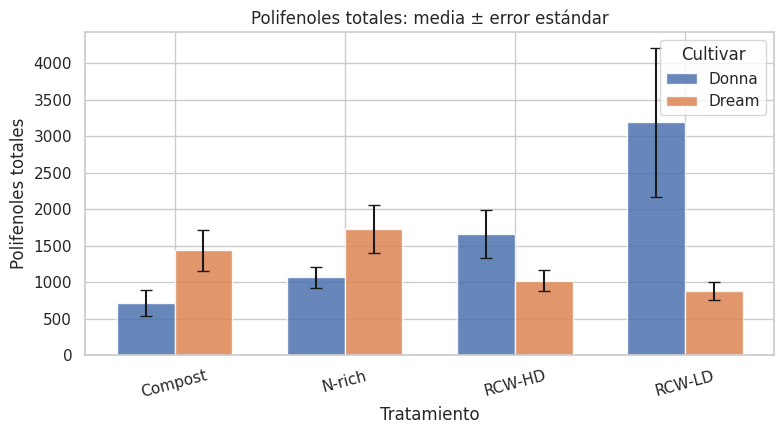

In [11]:
# Ejemplo Matplotlib: medias ± error estándar para dos outcomes clave.
for col, label in [('yield_g/planta','Rendimiento (g/planta)'),('Total polyphenols','Polifenoles totales')]:
    if col not in ana.columns:
        continue
    g=(ana.groupby(['Treatment_name','Cultivar'])[col]
         .agg(['mean','sem']).reset_index())
    fig, ax=plt.subplots(figsize=(8,4.5))
    x=np.arange(len(TREATMENT_ORDER)); width=.34
    for j, cv in enumerate(['Donna','Dream']):
        tmp=(g[g['Cultivar']==cv].set_index('Treatment_name').reindex(TREATMENT_ORDER))
        ax.bar(x+(j-.5)*width,tmp['mean'],width,yerr=tmp['sem'],capsize=4,label=cv,alpha=.85)
    ax.set_xticks(x); ax.set_xticklabels(TREATMENT_ORDER,rotation=15)
    ax.set_title(f'{label}: media ± error estándar')
    ax.set_xlabel('Tratamiento'); ax.set_ylabel(label); ax.legend(title='Cultivar')
    plt.tight_layout(); plt.show()


## 3.4 Temporalidad en suelo y hoja

El suelo contiene 2022 y 2023. Las hojas incluyen mediciones de diciembre/marzo/mayo según el bloque. Visualizar la trayectoria ayuda a decidir si conviene utilizar valores puntuales o características de cambio (`delta`).


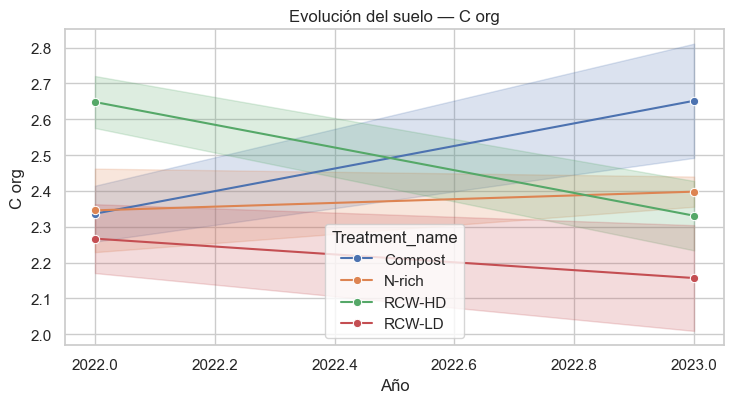

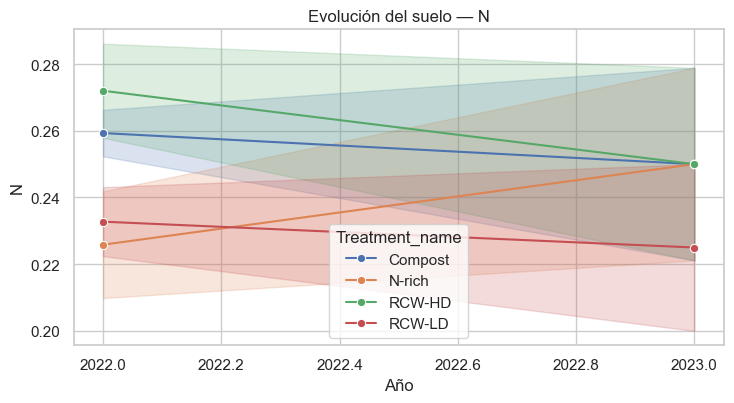

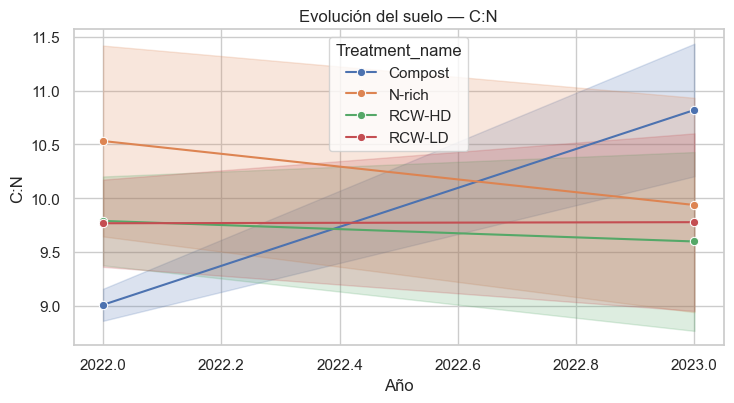

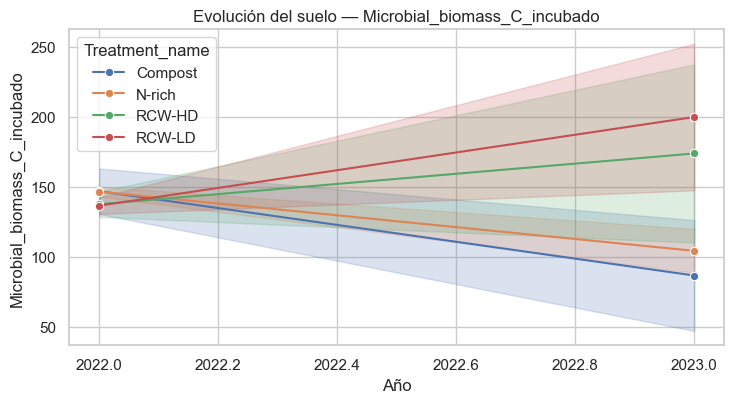

In [18]:
# Suelo 2022-2023 con nombres visibles de tratamiento.
soil_time=soil_raw.copy()
soil_time['Treatment_code']=clean_code(soil_time['Treatment']).str.replace('_','-',regex=False).map(SOIL_TO_T)
soil_time['Treatment_name']=soil_time['Treatment_code'].map(T_TO_NAME)

soil_time_vars=[c for c in ['C org','N','C:N','Microbial_biomass_C_incubado','Respiracion_microb (ug C-CO2/gsuelo·dia)'] if c in soil_time.columns]
for col in soil_time_vars[:4]:
    fig,ax=plt.subplots(figsize=(7.5,4.2))
    sns.lineplot(data=soil_time,x='Year',y=col,hue='Treatment_name',hue_order=TREATMENT_ORDER,
                 marker='o',errorbar='se',ax=ax)
    ax.set_title(f'Evolución del suelo — {col}')
    ax.set_xlabel('Año'); ax.set_ylabel(col)
    plt.tight_layout(); plt.show()


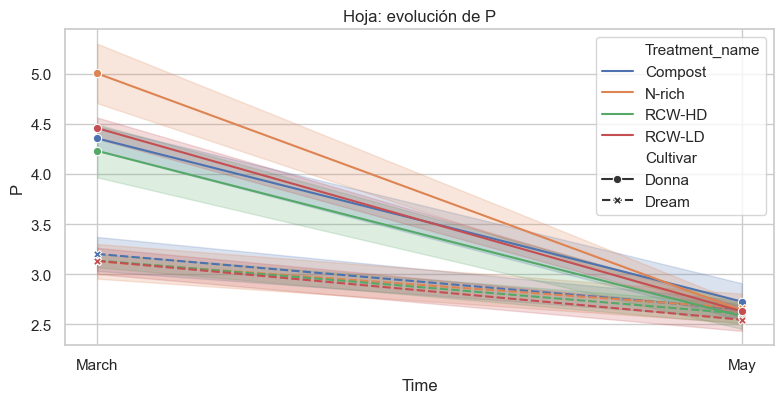

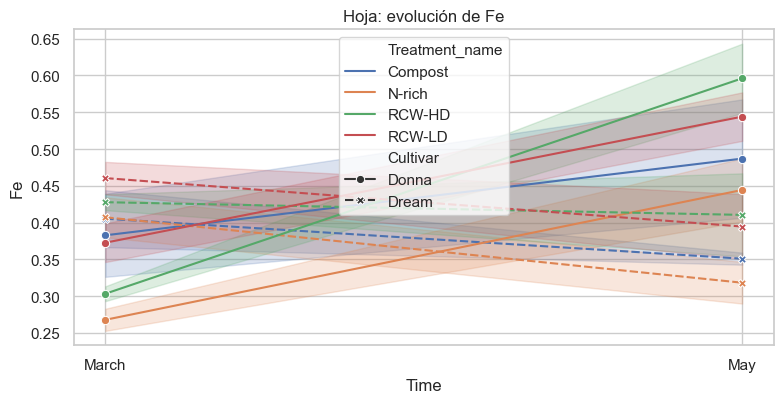

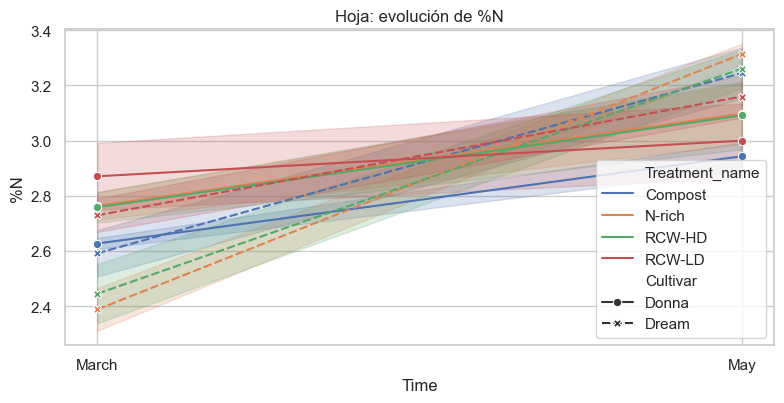

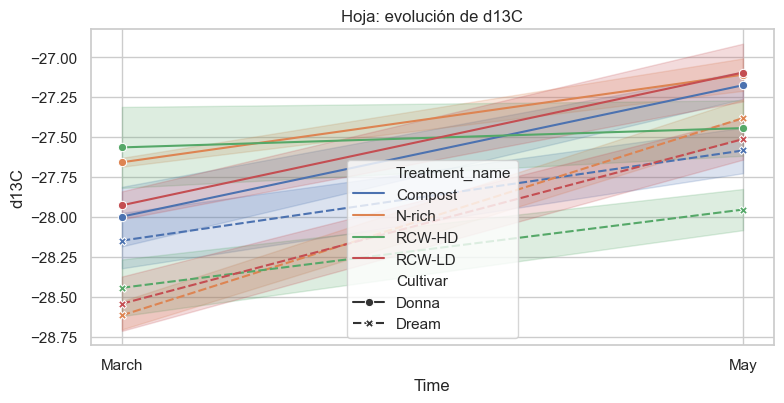

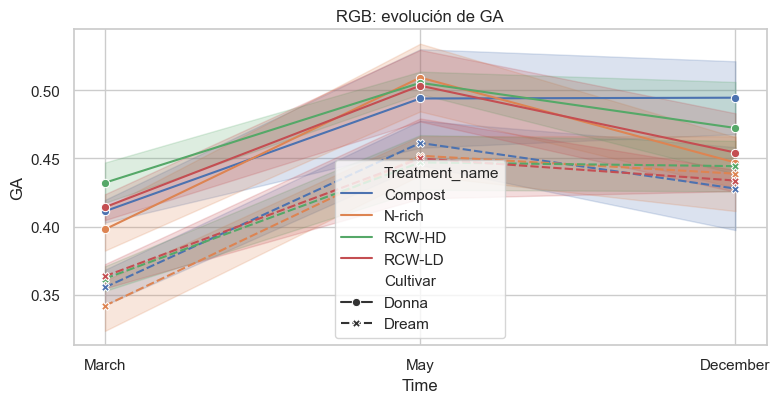

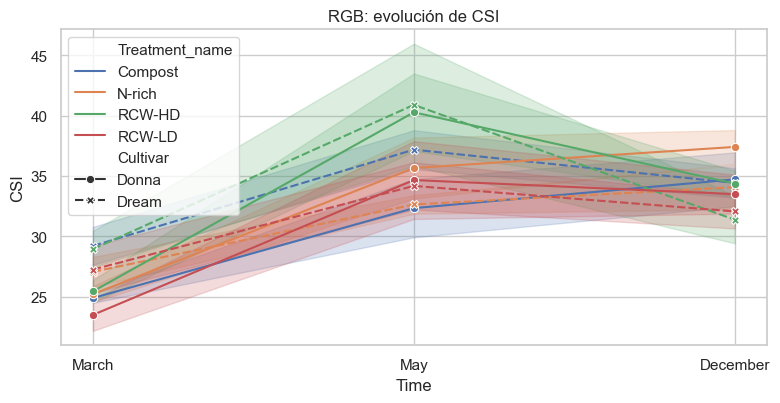

In [19]:
# Tendencias foliares seleccionadas.
# Nutrientes: P y Fe; isótopos: %N y d13C; RGB: GA y CSI.
nut_plot=nut_raw.copy()
nut_plot['Cultivar']=clean_cv(nut_plot['Cv'])
nut_plot['Treatment_name']=clean_code(nut_plot['Treatment']).map(T_TO_NAME)

for col in [c for c in ['P','Fe'] if c in nut_plot.columns]:
    fig,ax=plt.subplots(figsize=(8,4.2))
    sns.lineplot(data=nut_plot,x='Time',y=col,hue='Treatment_name',hue_order=TREATMENT_ORDER,
                 style='Cultivar',markers=True,errorbar='se',ax=ax)
    ax.set_title(f'Hoja: evolución de {col}')
    plt.tight_layout(); plt.show()

iso_plot=iso_raw.copy()
iso_plot['Cultivar']=clean_cv(iso_plot['Cv'])
iso_plot['Treatment_name']=clean_code(iso_plot['Treatment']).map(T_TO_NAME)
iso_plot['Time']=iso_plot['Date'].astype(str).str.extract('(March|May)',expand=False)
for col in [c for c in ['%N','d13C'] if c in iso_plot.columns]:
    fig,ax=plt.subplots(figsize=(8,4.2))
    sns.lineplot(data=iso_plot,x='Time',y=col,hue='Treatment_name',hue_order=TREATMENT_ORDER,
                 style='Cultivar',markers=True,errorbar='se',ax=ax)
    ax.set_title(f'Hoja: evolución de {col}')
    plt.tight_layout(); plt.show()

rgb_plot=rgb_raw.copy()
rgb_plot['Cultivar']=clean_cv(rgb_plot['Cv'])
rgb_plot['Treatment_name']=clean_code(rgb_plot['Treatment']).map(T_TO_NAME)
for col in [c for c in ['GA','CSI'] if c in rgb_plot.columns]:
    fig,ax=plt.subplots(figsize=(8,4.2))
    sns.lineplot(data=rgb_plot,x='Time',y=col,hue='Treatment_name',hue_order=TREATMENT_ORDER,
                 style='Cultivar',markers=True,errorbar='se',ax=ax)
    ax.set_title(f'RGB: evolución de {col}')
    plt.tight_layout(); plt.show()


## 3.5 Auditoría contextual de valores atípicos

Un valor extremo **no se eliminará automáticamente**. Dado que buscamos combinaciones especialmente favorables, un outlier alto puede representar una respuesta biológica real de interés.

La regla será:

> **Detectar → contextualizar Treatment/Cultivar/parcela → revisar coherencia con otras variables → conservar salvo evidencia de error.**


Casos variable-observación marcados por IQR: 133


,indice,variable,valor,Cultivar,Treatment_name,Replicate,Parcel_ID,limite_inferior,limite_superior,direccion,severidad_iqr
103,0,leaf_nut_Pb_March,31.058969,Donna,Compost,R1,T1_R1,0.747499,1.949458,alto,96.873555
91,23,leaf_nut_Mo_May,13.946345,Dream,N-rich,R4,T2_R4,-0.240582,0.536469,alto,69.029607
72,15,leaf_nut_Cd_March,1.286800,Donna,RCW-LD,R4,T4_R4,-0.036782,0.080166,alto,41.270956
74,2,leaf_nut_Cd_May,0.617643,Donna,Compost,R3,T1_R3,-0.031443,0.053204,alto,26.672611
107,16,leaf_nut_Pb_March,9.394810,Dream,Compost,R1,T1_R1,0.747499,1.949458,alto,24.777391
73,16,leaf_nut_Cd_March,0.655945,Dream,Compost,R1,T1_R1,-0.036782,0.080166,alto,19.693572
90,20,leaf_nut_Mo_May,3.911133,Dream,N-rich,R1,T2_R1,-0.240582,0.536469,alto,17.371654
93,31,leaf_nut_Mo_May,3.608754,Dream,RCW-LD,R4,T4_R4,-0.240582,0.536469,alto,15.815111
79,16,leaf_nut_Cd_May,0.338934,Dream,Compost,R1,T1_R1,-0.031443,0.053204,alto,13.502214
83,29,leaf_nut_Cr_May,12.739001,Dream,RCW-LD,R2,T4_R2,-1.000597,2.171653,alto,13.324736


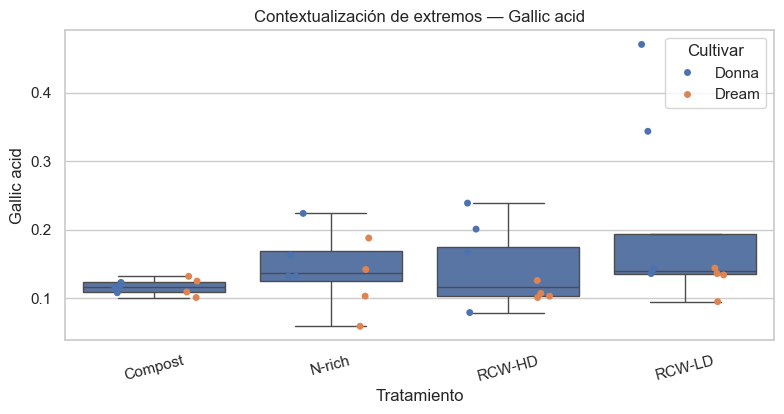

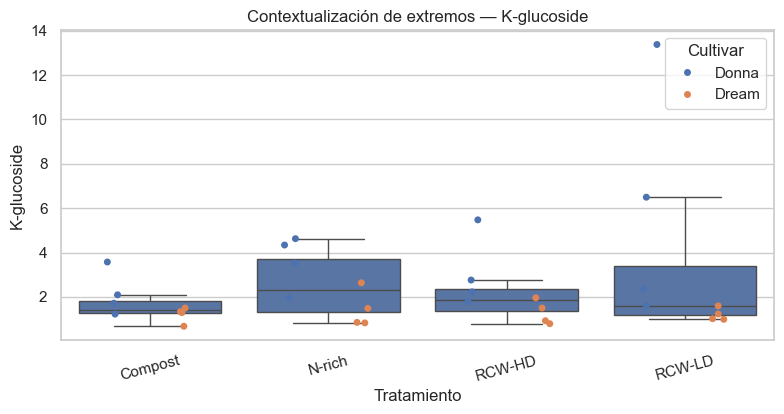

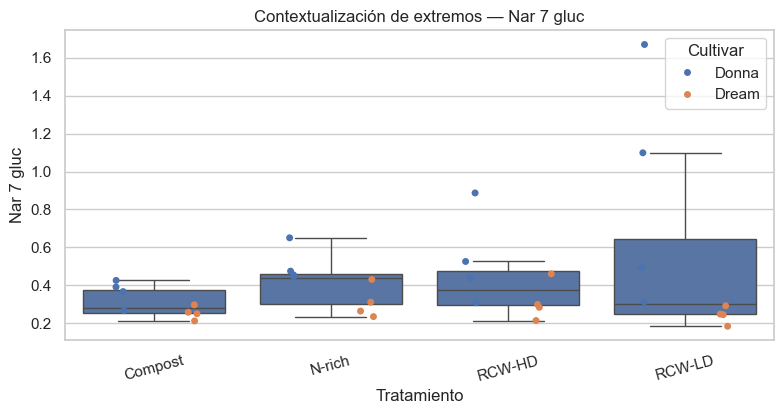

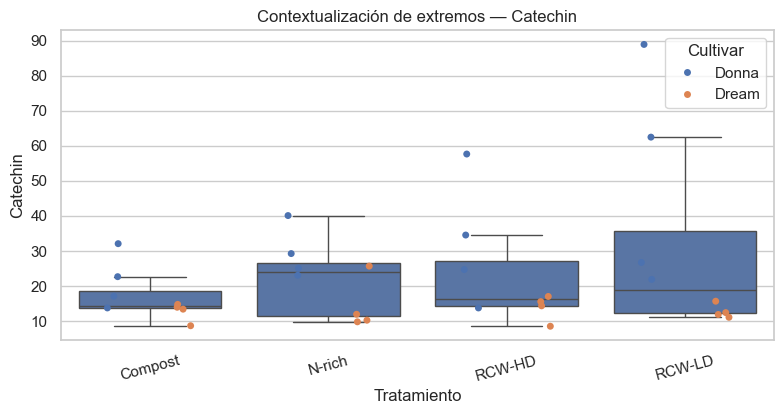

In [20]:
# Registro de atípicos IQR: detector, no regla de eliminación.
def build_outlier_registry(df, numeric_cols):
    rows=[]
    for col in numeric_cols:
        x=pd.to_numeric(df[col],errors='coerce')
        q1,q3=x.quantile(.25),x.quantile(.75); iqr=q3-q1
        if not np.isfinite(iqr) or iqr==0:
            continue
        lo,hi=q1-1.5*iqr,q3+1.5*iqr
        mask=(x<lo)|(x>hi)
        for idx in df.index[mask]:
            val=x.loc[idx]
            severity=(lo-val)/iqr if val<lo else (val-hi)/iqr
            rows.append({
                'indice':idx,'variable':col,'valor':val,
                'Cultivar':df.loc[idx,'Cultivar'],'Treatment_name':df.loc[idx,'Treatment_name'],
                'Replicate':df.loc[idx,'Replicate'],'Parcel_ID':df.loc[idx,'Parcel_ID'],
                'limite_inferior':lo,'limite_superior':hi,
                'direccion':'bajo' if val<lo else 'alto','severidad_iqr':severity
            })
    return pd.DataFrame(rows)

all_numeric=[c for c in ana.select_dtypes(include=np.number).columns]
outlier_registry=build_outlier_registry(ana,all_numeric)
print('Casos variable-observación marcados por IQR:',len(outlier_registry))
display(outlier_registry.sort_values('severidad_iqr',ascending=False).head(20))

# Contexto de los outliers más severos en outcomes principales.
outcome_set=set(production_cols+physchem_cols+nutritional_cols)
outcome_outliers=outlier_registry[outlier_registry['variable'].isin(outcome_set)].copy()
if not outcome_outliers.empty:
    top_vars=outcome_outliers.groupby('variable')['severidad_iqr'].max().sort_values(ascending=False).head(4).index
    for col in top_vars:
        fig,ax=plt.subplots(figsize=(8,4.3))
        sns.boxplot(data=ana,x='Treatment_name',y=col,order=TREATMENT_ORDER,showfliers=False,ax=ax)
        sns.stripplot(data=ana,x='Treatment_name',y=col,hue='Cultivar',order=TREATMENT_ORDER,dodge=True,ax=ax)
        ax.set_title(f'Contextualización de extremos — {col}')
        ax.set_xlabel('Tratamiento')
        plt.xticks(rotation=15); plt.tight_layout(); plt.show()


## 3.6 Relaciones entre bloques: Spearman + Benjamini-Hochberg (FDR)

Las correlaciones se calculan **por cultivar** para reducir el problema de duplicar la misma condición de suelo al comparar Donna y Dream dentro de una parcela. Se controlará la tasa de falsos descubrimientos mediante Benjamini-Hochberg.

Se priorizan tres relaciones:

1. **Suelo ↔ calidad del fruto**.
2. **Nutrición foliar ↔ calidad del fruto**.
3. **RGB/fisiología ↔ calidad del fruto**.

La correlación describe asociación, no causalidad.


In [21]:
def spearman_cross_block(df, x_cols, y_cols, label, min_n=10):
    rows=[]
    for cv in sorted(df['Cultivar'].dropna().unique()):
        d=df[df['Cultivar']==cv]
        for x in x_cols:
            for y in y_cols:
                pair=d[[x,y]].dropna()
                if len(pair)<min_n or pair[x].nunique()<3 or pair[y].nunique()<3:
                    continue
                rho,p=spearmanr(pair[x],pair[y])
                if np.isfinite(rho) and np.isfinite(p):
                    rows.append({'Relación':label,'Cultivar':cv,'X':x,'Y':y,'n':len(pair),'rho':rho,'p':p})
    out=pd.DataFrame(rows)
    if not out.empty:
        out['q_FDR']=np.nan
        for (rel,cv),idx in out.groupby(['Relación','Cultivar']).groups.items():
            out.loc[idx,'q_FDR']=multipletests(out.loc[idx,'p'],method='fdr_bh')[1]
    return out

fruit_quality_cols=[c for c in production_cols+physchem_cols+['Total polyphenols','Tot anth','Vit C'] if c in ana.columns]
leaf_selected=[c for c in leaf_nutrition_cols if any(k in c for k in ['_P_','_Fe_','_Ca_','_Mg_','_%N_','d13C','NO3'])]

corr_tables=[]
corr_tables.append(spearman_cross_block(ana,soil_cols,fruit_quality_cols,'Suelo → fruto'))
corr_tables.append(spearman_cross_block(ana,leaf_selected,fruit_quality_cols,'Nutrición hoja → fruto'))
corr_tables.append(spearman_cross_block(ana,rgb_cols,fruit_quality_cols,'RGB → fruto'))
corr_results=pd.concat([x for x in corr_tables if not x.empty],ignore_index=True)

if not corr_results.empty:
    sig=corr_results[corr_results['q_FDR']<.05].sort_values(['q_FDR','rho'],key=lambda s:s.abs() if s.name=='rho' else s)
    print('Asociaciones evaluadas:',len(corr_results),'| q_FDR < 0.05:',len(sig))
    display((sig if not sig.empty else corr_results.sort_values('q_FDR').head(25)).head(30))
else:
    print('No se generaron correlaciones con el mínimo de observaciones requerido.')


Asociaciones evaluadas: 945 | q_FDR < 0.05: 1


,Relación,Cultivar,X,Y,n,rho,p,q_FDR
937,RGB → fruto,Dream,leaf_rgb_GGA_May,fruit_Firm,16,-0.779088,0.000375,0.047271


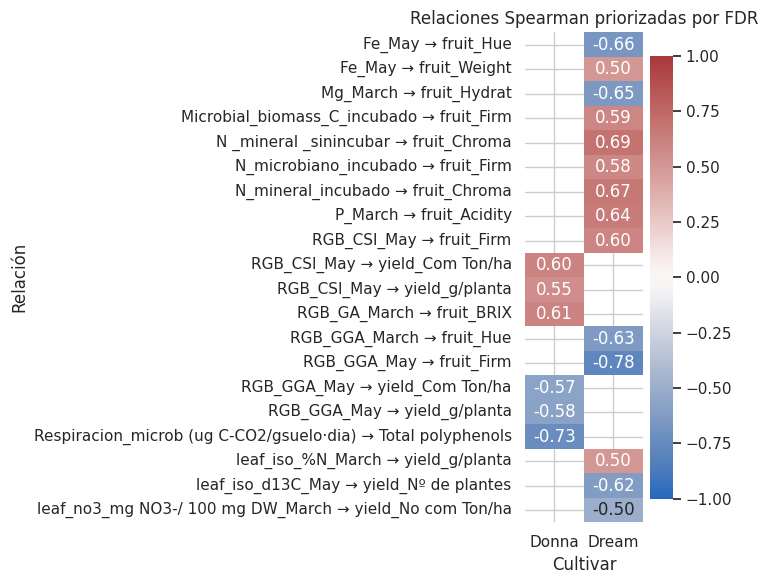

In [16]:
# Heatmap compacto: las 20 asociaciones con menor q-FDR, por cultivar.
if not corr_results.empty:
    top=corr_results.sort_values('q_FDR').head(20).copy()
    top['par']=top['X'].str.replace('leaf_nut_','',regex=False).str.replace('soil_','',regex=False).str.replace('leaf_rgb_','RGB_',regex=False) + ' → ' + top['Y']
    heat=top.pivot_table(index='par',columns='Cultivar',values='rho',aggfunc='first')
    fig,ax=plt.subplots(figsize=(7,max(5,.3*len(heat))))
    sns.heatmap(heat,cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',ax=ax)
    ax.set_title('Relaciones Spearman priorizadas por FDR')
    ax.set_xlabel('Cultivar'); ax.set_ylabel('Relación')
    plt.tight_layout(); plt.show()


# 4. Transformaciones y preparación para modelado


> **Política de outliers:** no se eliminan automáticamente. Las transformaciones buscan estabilidad numérica, no borrar respuestas extremas.


In [22]:
# Ingeniería temporal: baseline + delta, reutilizando la lógica de Avance 2.
def feature_builder(df):
    z=df.copy(); created={}; removed=[]; original=list(z.columns)

    for family in ['leaf_iso_','leaf_no3_','leaf_nut_']:
        may_cols=[c for c in original if c.startswith(family) and c.endswith('_May')]
        for may in may_cols:
            march=may[:-3]+'March'
            if march in z.columns:
                new='FE_delta_'+may.replace('_May','')
                z[new]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[march],errors='coerce')
                created[new]=f'Cambio May - March; baseline conservado en {march}.'
                removed.append(may)

    rgb_metrics=sorted({c.rsplit('_',1)[0] for c in original if c.startswith('leaf_rgb_')})
    for base in rgb_metrics:
        dec,mar,may=base+'_December',base+'_March',base+'_May'
        if dec in z and mar in z:
            d1='FE_delta_'+base+'_March_minus_December'
            z[d1]=pd.to_numeric(z[mar],errors='coerce')-pd.to_numeric(z[dec],errors='coerce')
            created[d1]=f'Cambio March - December para {base}; December funciona como baseline.'
            removed.append(mar)
        if mar in z and may in z:
            d2='FE_delta_'+base+'_May_minus_March'
            z[d2]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[mar],errors='coerce')
            created[d2]=f'Cambio May - March para {base}.'
            removed.append(may)

    removed=list(dict.fromkeys([c for c in removed if c in z.columns]))
    z=z.drop(columns=removed)
    return z,created,removed

ana_fe, derived, temporal_removed = feature_builder(ana)

soil_fe=[c for c in ana_fe if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana_fe[c])]
leaf_fe=[c for c in ana_fe if (c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) or c.startswith(('FE_delta_leaf_nut_','FE_delta_leaf_iso_','FE_delta_leaf_no3_'))) and pd.api.types.is_numeric_dtype(ana_fe[c])]
rgb_fe=[c for c in ana_fe if (c.startswith('leaf_rgb_') or c.startswith('FE_delta_leaf_rgb_')) and pd.api.types.is_numeric_dtype(ana_fe[c])]
X_fe_cols=list(dict.fromkeys(soil_fe+leaf_fe+rgb_fe))

work_cols=list(dict.fromkeys(['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment'] + X_fe_cols + production_cols + physchem_cols + nutritional_cols))
work=ana_fe[work_cols].copy().replace([np.inf,-np.inf],np.nan)

print('Predictores originales suelo+hoja+RGB:',len(X_raw_cols))
print('Predictores después de FE temporal:',len(X_fe_cols))
print('Características delta creadas:',len(derived))
print('Mediciones finales redundantes retiradas:',len(temporal_removed))


Predictores originales suelo+hoja+RGB: 64
Predictores después de FE temporal: 64
Características delta creadas: 28
Mediciones finales redundantes retiradas: 28


In [23]:
# Split por parcela para evitar que información compartida de suelo aparezca en train y test.
from sklearn.model_selection import GroupShuffleSplit

split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED)
itr,ite=next(split.split(work, groups=work['Parcel_ID']))
tr=work.iloc[itr].copy(); te=work.iloc[ite].copy()

assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
print('Entrenamiento:',tr.shape,'| Prueba:',te.shape)
print('Parcelas train/test:',tr.Parcel_ID.nunique(),te.Parcel_ID.nunique())
print('Overlap de parcelas:',set(tr.Parcel_ID)&set(te.Parcel_ID))
print('Parcelas test:',sorted(te.Parcel_ID.unique()))


Entrenamiento: (24, 103) | Prueba: (8, 103)
Parcelas train/test: 12 4
Overlap de parcelas: set()
Parcelas test: ['T1_R4', 'T3_R3', 'T4_R2', 'T4_R3']


In [24]:
# Imputación, Yeo-Johnson, escalamiento y OHE. Todo se ajusta SOLO con train.
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder

numeric_candidates=[c for c in X_fe_cols if c in tr.columns and pd.api.types.is_numeric_dtype(tr[c])]
all_missing=[c for c in numeric_candidates if tr[c].notna().sum()==0]
num_cols=[c for c in numeric_candidates if c not in all_missing]
assert num_cols, 'Sin predictores numéricos disponibles.'

imputer=SimpleImputer(strategy='median')
Xtr0=pd.DataFrame(imputer.fit_transform(tr[num_cols]),columns=num_cols,index=tr.index)
Xte0=pd.DataFrame(imputer.transform(te[num_cols]),columns=num_cols,index=te.index)

sk0=Xtr0.apply(lambda x: skew(x.to_numpy(),bias=False) if x.nunique()>2 else 0).replace([np.inf,-np.inf],0).fillna(0)
transformed=[c for c in num_cols if abs(sk0[c])>1 and Xtr0[c].nunique()>3]
Xtr1=Xtr0.copy(); Xte1=Xte0.copy(); transformers={}; diagnostics=[]
for c in transformed:
    pt=PowerTransformer(method='yeo-johnson',standardize=False)
    try:
        Xtr1[c]=pt.fit_transform(Xtr0[[c]]).ravel()
        Xte1[c]=pt.transform(Xte0[[c]]).ravel()
        transformers[c]=pt
        diagnostics.append({'variable':c,'skew_antes':float(sk0[c]),'skew_despues':float(skew(Xtr1[c],bias=False))})
    except (ValueError,FloatingPointError) as e:
        Xtr1[c]=Xtr0[c]; Xte1[c]=Xte0[c]
        print('Yeo-Johnson omitida:',c,str(e))

scaler=StandardScaler()
Xtr_num=pd.DataFrame(scaler.fit_transform(Xtr1),index=tr.index,columns=num_cols)
Xte_num=pd.DataFrame(scaler.transform(Xte1),index=te.index,columns=num_cols)

try:
    ohe=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:
    ohe=OneHotEncoder(handle_unknown='ignore',sparse=False)
cat_cols=['Cultivar','Treatment']
Xtr_cat=pd.DataFrame(ohe.fit_transform(tr[cat_cols]),index=tr.index,columns=ohe.get_feature_names_out(cat_cols))
Xte_cat=pd.DataFrame(ohe.transform(te[cat_cols]),index=te.index,columns=ohe.get_feature_names_out(cat_cols))

transform_report=pd.DataFrame(diagnostics,columns=['variable','skew_antes','skew_despues'])
print('Candidatas X:',len(numeric_candidates),'| Yeo-Johnson:',len(transformers),'| OHE:',Xtr_cat.shape[1])
display(transform_report.sort_values('skew_antes',key=lambda s:s.abs(),ascending=False).head(15) if not transform_report.empty else pd.DataFrame({'mensaje':['Sin Yeo-Johnson necesaria']}))


Candidatas X: 64 | Yeo-Johnson: 16 | OHE: 6


,variable,skew_antes,skew_despues
8,leaf_nut_Pb_March,4.368644,0.346580
15,FE_delta_leaf_nut_Pb,-4.009575,0.555208
14,FE_delta_leaf_nut_Mo,3.961248,0.192237
4,leaf_nut_Cu_March,3.788146,-0.004430
2,leaf_nut_Cd_March,3.763032,1.691159
13,FE_delta_leaf_nut_Cd,-2.790137,0.512238
7,leaf_nut_Ni_March,2.419698,-0.022918
9,leaf_nut_Si_March,1.844014,0.274869
6,leaf_nut_Na_March,1.706277,0.174099
1,soil_N_microbiano_incubado,1.534185,-0.019567


In [25]:
# Filtros no supervisados: varianza, duplicados y correlación Spearman extrema.
filter_log=[]
var=Xtr_num.var(ddof=0)
keep=[c for c in num_cols if var[c]>1e-12]
for c in num_cols:
    if c not in keep:
        filter_log.append({'Feature':c,'Etapa':'Variance threshold','Razón':'Varianza nula en entrenamiento'})

nondup=[]
for c in keep:
    copied=next((d for d in nondup if np.allclose(Xtr_num[c].to_numpy(),Xtr_num[d].to_numpy(),atol=1e-10,rtol=1e-10)),None)
    if copied:
        filter_log.append({'Feature':c,'Etapa':'Duplicate','Razón':'Duplicado exacto de '+copied})
    else:
        nondup.append(c)

def priority_feature(name):
    return (name.startswith('FE_'), name)

selected_corr=[]; high_corr=[]
for c in sorted(nondup,key=priority_feature):
    conflict=None
    for d in selected_corr:
        rho=spearmanr(Xtr_num[c],Xtr_num[d]).statistic
        if np.isfinite(rho) and abs(rho)>=0.95:
            conflict=(d,rho); break
    if conflict:
        filter_log.append({'Feature':c,'Etapa':'Correlation','Razón':f'Spearman {conflict[1]:.3f} con {conflict[0]}'})
        high_corr.append({'Variable_conservada':conflict[0],'Variable_retirada':c,'Spearman':conflict[1]})
    else:
        selected_corr.append(c)

Xtr_depurado=pd.concat([Xtr_num[selected_corr],Xtr_cat],axis=1)
Xte_depurado=pd.concat([Xte_num[selected_corr],Xte_cat],axis=1)

print('Numéricas candidatas:',len(num_cols),'→ no redundantes:',len(selected_corr),'→ matriz final:',Xtr_depurado.shape[1])
display(pd.DataFrame(high_corr).head(20) if high_corr else pd.DataFrame({'mensaje':['Sin pares >= 0.95']}))


Numéricas candidatas: 64 → no redundantes: 62 → matriz final: 68


,Variable_conservada,Variable_retirada,Spearman
0,leaf_no3_mg NO3-/ 100 mg DW_March,leaf_no3_mg NO3-/ g DW_March,0.950435
1,FE_delta_leaf_no3_mg NO3-/ 100 mg DW,FE_delta_leaf_no3_mg NO3-/ g DW,0.973043


## 4.1 PCA por bloques y PCA global

PCA se mantiene como técnica de **extracción de características**. No se interpreta como una verdad biológica, sino como una representación compacta de la estructura de variación.


,Bloque,Variables,PC_80,PC_85,Var_85_real
0,Suelo,11,4,4,86.30
1,Hoja_nutricion,42,9,10,86.21
2,RGB_fisiologia,9,3,3,86.53
3,Global_X,62,10,11,86.09


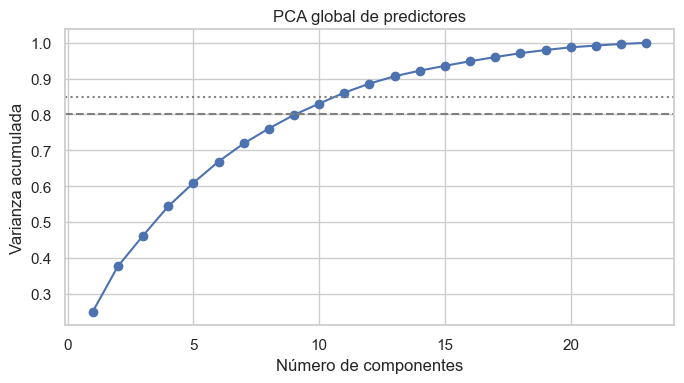

In [26]:
from sklearn.decomposition import PCA

pca_results={}; pca_summary=[]

def pca_processed_block(name, cols):
    cols=[c for c in cols if c in selected_corr]
    if len(cols)<2:
        return None
    max_comp=min(len(cols),len(Xtr_num)-1)
    p_full=PCA(n_components=max_comp,random_state=SEED).fit(Xtr_num[cols])
    cum=np.cumsum(p_full.explained_variance_ratio_)
    n80=int(np.searchsorted(cum,.80)+1); n85=int(np.searchsorted(cum,.85)+1)
    n_use=max(2,n85)
    p=PCA(n_components=n_use,random_state=SEED)
    tr_scores=p.fit_transform(Xtr_num[cols]); te_scores=p.transform(Xte_num[cols])
    pcs=[f'PC{i+1}' for i in range(n_use)]
    scores=pd.concat([pd.DataFrame(tr_scores,index=tr.index,columns=pcs),pd.DataFrame(te_scores,index=te.index,columns=pcs)]).sort_index()
    load=pd.DataFrame(p.components_.T,index=cols,columns=pcs)
    pca_results[name]={'pca':p,'scores':scores,'loadings':load,'cols':cols}
    pca_summary.append({'Bloque':name,'Variables':len(cols),'PC_80':n80,'PC_85':n85,'Var_85_real':100*cum[n85-1]})
    return pca_results[name]

pca_processed_block('Suelo',soil_fe)
pca_processed_block('Hoja_nutricion',leaf_fe)
pca_processed_block('RGB_fisiologia',rgb_fe)

# PCA global sobre predictores depurados numéricos.
max_comp=min(len(selected_corr),len(Xtr_num)-1)
pca_full=PCA(n_components=max_comp,random_state=SEED).fit(Xtr_num[selected_corr])
cum=np.cumsum(pca_full.explained_variance_ratio_)
n85=int(np.searchsorted(cum,.85)+1)
pca_global=PCA(n_components=max(2,n85),random_state=SEED)
P_tr=pca_global.fit_transform(Xtr_num[selected_corr]); P_te=pca_global.transform(Xte_num[selected_corr])
pca_cols=[f'PC{i+1}' for i in range(P_tr.shape[1])]
pca_scores=pd.concat([pd.DataFrame(P_tr,index=tr.index,columns=pca_cols),pd.DataFrame(P_te,index=te.index,columns=pca_cols)]).sort_index()
pca_loadings=pd.DataFrame(pca_global.components_.T,index=selected_corr,columns=pca_cols)
pca_summary.append({'Bloque':'Global_X','Variables':len(selected_corr),'PC_80':int(np.searchsorted(cum,.80)+1),'PC_85':n85,'Var_85_real':100*cum[n85-1]})

display(pd.DataFrame(pca_summary).round(2))

fig,ax=plt.subplots(figsize=(7,4))
ax.plot(range(1,len(cum)+1),cum,marker='o')
ax.axhline(.80,linestyle='--',color='gray'); ax.axhline(.85,linestyle=':',color='gray')
ax.set(xlabel='Número de componentes',ylabel='Varianza acumulada',title='PCA global de predictores')
plt.tight_layout(); plt.show()


# 5. Modelo baseline

### ¿Qué haremos?
Construiremos dos referencias:

1. **Baseline ingenuo:** `DummyRegressor(strategy="mean")`.
2. **Baseline aprendido:** `Ridge Regression` con regularización.

### ¿Por qué?
Todos los objetivos relevantes son continuos, por lo que el problema se plantea como **regresión**. El Dummy establece cuánto error tendríamos sin aprender relaciones. Ridge representa una solución simple, interpretable y apropiada para variables correlacionadas.

### ¿Qué esperamos obtener?
Determinar si los datos contienen señal predictiva por encima de una regla mínima y establecer una referencia contra la cual comparar modelos más complejos.

## 5.1 Variables objetivo

No utilizaremos `yield_g/planta` como único target. Evaluaremos outcomes representativos de las tres familias:

- **Producción:** g/planta y Ton/ha comercial.
- **Fisicoquímica:** BRIX y acidez.
- **Nutricional:** polifenoles totales, antocianinas totales y vitamina C.

Los predictores serán únicamente **suelo + hoja + RGB + cultivar + tratamiento**. No se utilizará otra variable de fruto para predecir un outcome del fruto, evitando *target leakage*.


In [27]:
# Targets principales para el benchmark predictivo.
MODEL_TARGETS = {
    'Rendimiento g/planta':'yield_g/planta',
    'Producción comercial Ton/ha':'yield_Com Ton/ha',
    'BRIX':'fruit_BRIX',
    'Acidez':'fruit_Acidity',
    'Polifenoles totales':'Total polyphenols',
    'Antocianinas totales':'Tot anth',
    'Vitamina C':'Vit C',
}
MODEL_TARGETS={label:col for label,col in MODEL_TARGETS.items() if col in work.columns}

target_availability=pd.DataFrame([
    {'Objetivo':label,'Columna':col,'n total':int(work[col].notna().sum()),
     'n train':int(tr[col].notna().sum()),'n test':int(te[col].notna().sum())}
    for label,col in MODEL_TARGETS.items()
])
display(target_availability)


,Objetivo,Columna,n total,n train,n test
0,Rendimiento g/planta,yield_g/planta,32,24,8
1,Producción comercial Ton/ha,yield_Com Ton/ha,32,24,8
2,BRIX,fruit_BRIX,32,24,8
3,Acidez,fruit_Acidity,32,24,8
4,Polifenoles totales,Total polyphenols,32,24,8
5,Antocianinas totales,Tot anth,29,21,8
6,Vitamina C,Vit C,32,24,8


## 5.2 Métricas y desempeño mínimo

### Métrica principal: MAE

Usaremos **MAE (Mean Absolute Error)** como métrica principal porque expresa el error en las mismas unidades del outcome y es menos sensible que RMSE a observaciones extremas legítimas.

También reportaremos:

- **RMSE:** penaliza errores grandes.
- **R²:** proporción de variabilidad explicada; con muestras pequeñas puede ser inestable y debe interpretarse con cautela.

### Criterio mínimo de viabilidad

Como no existe un benchmark histórico de ML para este experimento, se define un criterio interno:

> Un modelo aprendido se considerará **mínimamente útil** si reduce el MAE de validación cruzada al menos **10% respecto a DummyRegressor** y obtiene `R² > 0` en validación.

El 10% no es una verdad científica; es una regla de proyecto para decidir si vale la pena invertir en modelos más complejos.


In [28]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge

rmse_scorer=make_scorer(lambda y_true,y_pred: np.sqrt(mean_squared_error(y_true,y_pred)),greater_is_better=False)
SCORING={'mae':'neg_mean_absolute_error','rmse':rmse_scorer,'r2':'r2'}

BASE_MODELS={
    'Dummy (media)':DummyRegressor(strategy='mean'),
    'Ridge baseline':Ridge(alpha=10.0),
}

def evaluate_model(name, model, target_label, target_col):
    mtr=tr[target_col].notna(); mte=te[target_col].notna()
    X_train=Xtr_depurado.loc[mtr]; y_train=tr.loc[mtr,target_col].astype(float); groups=tr.loc[mtr,'Parcel_ID']
    X_test=Xte_depurado.loc[mte]; y_test=te.loc[mte,target_col].astype(float)
    n_groups=groups.nunique(); n_splits=min(4,n_groups)
    if len(y_train)<12 or n_splits<3:
        return None
    cv=GroupKFold(n_splits=n_splits)
    res=cross_validate(model,X_train,y_train,groups=groups,cv=cv,scoring=SCORING,return_train_score=True,error_score='raise',n_jobs=-1)
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    pred=np.asarray(pred).reshape(-1)
    hold_mae=mean_absolute_error(y_test,pred) if len(y_test)>=1 else np.nan
    hold_rmse=np.sqrt(mean_squared_error(y_test,pred)) if len(y_test)>=1 else np.nan
    hold_r2=r2_score(y_test,pred) if len(y_test)>=2 else np.nan
    return {
        'Objetivo':target_label,'Target':target_col,'Modelo':name,
        'n_train':len(y_train),'n_test':len(y_test),
        'Train_MAE':-np.mean(res['train_mae']),
        'CV_MAE':-np.mean(res['test_mae']),
        'CV_MAE_sd':np.std(-res['test_mae']),
        'CV_RMSE':-np.mean(res['test_rmse']),
        'CV_R2':np.mean(res['test_r2']),
        'Holdout_MAE':hold_mae,'Holdout_RMSE':hold_rmse,'Holdout_R2':hold_r2,
        'Overfit_ratio_CV_vs_train':(-np.mean(res['test_mae']))/max(-np.mean(res['train_mae']),1e-12)
    }

baseline_rows=[]
for label,col in MODEL_TARGETS.items():
    for model_name,model in BASE_MODELS.items():
        row=evaluate_model(model_name,model,label,col)
        if row: baseline_rows.append(row)

baseline_results=pd.DataFrame(baseline_rows)
# Mejora de Ridge vs Dummy por objetivo.
dummy_mae=baseline_results[baseline_results.Modelo=='Dummy (media)'].set_index('Objetivo')['CV_MAE']
baseline_results['Mejora_vs_Dummy_%']=baseline_results.apply(
    lambda r: 100*(dummy_mae.get(r['Objetivo'],np.nan)-r['CV_MAE'])/dummy_mae.get(r['Objetivo'],np.nan),axis=1)
baseline_results['Cumple_minimo']=(baseline_results['Mejora_vs_Dummy_%']>=10)&(baseline_results['CV_R2']>0)&(baseline_results['Modelo']!='Dummy (media)')

display(baseline_results.round(3))


,Objetivo,Target,Modelo,n_train,n_test,Train_MAE,CV_MAE,CV_MAE_sd,CV_RMSE,CV_R2,Holdout_MAE,Holdout_RMSE,Holdout_R2,Overfit_ratio_CV_vs_train,Mejora_vs_Dummy_%,Cumple_minimo
0,Rendimiento g/planta,yield_g/planta,Dummy (media),24,8,137.446,137.446,12.016,148.011,-0.015,124.286,131.192,-0.008,1.000,0.000,False
1,Rendimiento g/planta,yield_g/planta,Ridge baseline,24,8,10.682,42.204,8.730,49.721,0.884,81.936,99.248,0.423,3.951,69.294,True
2,Producción comercial Ton/ha,yield_Com Ton/ha,Dummy (media),24,8,2.374,2.374,0.226,2.504,-0.008,2.262,2.362,-0.018,1.000,0.000,False
3,Producción comercial Ton/ha,yield_Com Ton/ha,Ridge baseline,24,8,0.165,0.646,0.095,0.765,0.905,1.501,1.697,0.474,3.907,72.797,True
4,BRIX,fruit_BRIX,Dummy (media),24,8,0.579,0.597,0.132,0.751,-0.311,0.735,0.897,-0.097,1.031,0.000,False
5,BRIX,fruit_BRIX,Ridge baseline,24,8,0.128,0.609,0.020,0.730,-0.334,0.760,0.916,-0.143,4.767,-1.977,False
6,Acidez,fruit_Acidity,Dummy (media),24,8,0.047,0.048,0.015,0.059,-0.134,0.032,0.049,-0.174,1.025,0.000,False
7,Acidez,fruit_Acidity,Ridge baseline,24,8,0.013,0.045,0.012,0.052,-0.026,0.062,0.076,-1.887,3.360,6.467,False
8,Polifenoles totales,Total polyphenols,Dummy (media),24,8,560.297,580.130,211.046,776.281,-0.543,1078.963,1541.373,-0.084,1.035,0.000,False
9,Polifenoles totales,Total polyphenols,Ridge baseline,24,8,165.130,757.732,204.463,1030.370,-2.175,1392.552,2051.053,-0.919,4.589,-30.614,False


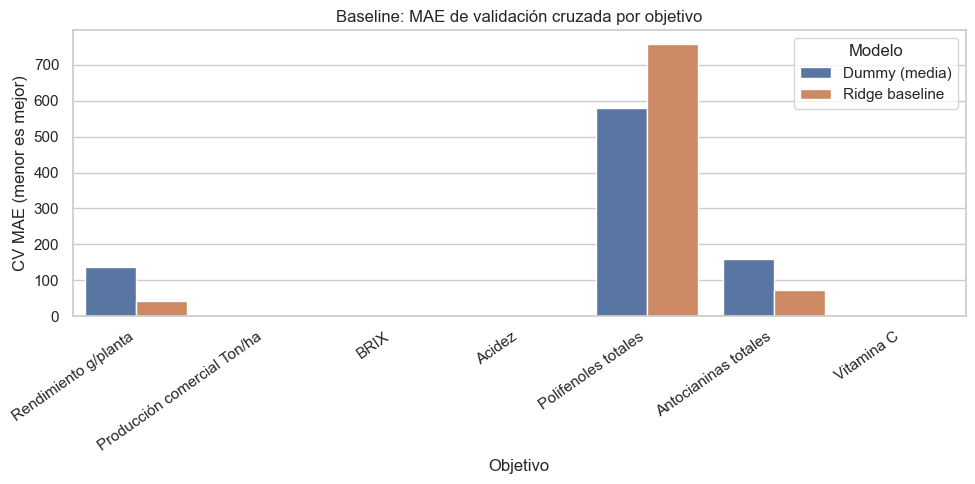

,Objetivo,CV_MAE,CV_R2,Mejora_vs_Dummy_%,Cumple_minimo
1,Rendimiento g/planta,42.204,0.884,69.294,True
3,Producción comercial Ton/ha,0.646,0.905,72.797,True
5,BRIX,0.609,-0.334,-1.977,False
7,Acidez,0.045,-0.026,6.467,False
9,Polifenoles totales,757.732,-2.175,-30.614,False
11,Antocianinas totales,74.400,0.686,53.598,True
13,Vitamina C,0.814,-1.192,-18.473,False


In [30]:
# Visualización del baseline aprendido frente al ingenuo.
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=baseline_results,x='Objetivo',y='CV_MAE',hue='Modelo',ax=ax)
ax.set_title('Baseline: MAE de validación cruzada por objetivo')
ax.set_xlabel('Objetivo'); ax.set_ylabel('CV MAE (menor es mejor)')
plt.xticks(rotation=35,ha='right'); plt.tight_layout(); plt.show()

ridge_summary=baseline_results[baseline_results['Modelo']=='Ridge baseline'][['Objetivo','CV_MAE','CV_R2','Mejora_vs_Dummy_%','Cumple_minimo']]
display(ridge_summary.round(3))


# 6. Modelos y algoritmos

En este capítulo se desarrollan dos familias complementarias:

1. **Modelos explicativos/inferenciales:** ANOVA, LMM, correlaciones y RDA.
2. **Modelos predictivos:** Ridge, Elastic Net, PLS, PCA+Ridge y Random Forest.

No se busca que un solo algoritmo responda todas las preguntas.


## 6.1 Efecto de tratamiento, cultivar e interacción: ANOVA de dos vías

Para cada outcome se estima:

`Outcome ~ Treatment + Cultivar + Treatment × Cultivar`

Luego se aplica Benjamini-Hochberg por tipo de efecto para controlar comparaciones múltiples.


In [31]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

anova_outcomes=list(dict.fromkeys(production_cols+physchem_cols+[c for c in nutritional_cols if c in work.columns]))
anova_rows=[]
for col in anova_outcomes:
    d=work[['Treatment_name','Cultivar','Replicate','Parcel_ID',col]].dropna().copy()
    if len(d)<16 or d[col].nunique()<4:
        continue
    try:
        fit=smf.ols(f'Q("{col}") ~ C(Treatment_name) * C(Cultivar)',data=d).fit()
        tab=anova_lm(fit,typ=2)
        effects={
            'Treatment':'C(Treatment_name)',
            'Cultivar':'C(Cultivar)',
            'Interaction':'C(Treatment_name):C(Cultivar)'
        }
        for label,rowname in effects.items():
            if rowname in tab.index:
                anova_rows.append({'Outcome':col,'Efecto':label,'F':tab.loc[rowname,'F'],'p':tab.loc[rowname,'PR(>F)']})
    except Exception as e:
        print('ANOVA omitido:',col,'|',e)

anova_results=pd.DataFrame(anova_rows)
if not anova_results.empty:
    anova_results['q_FDR']=np.nan
    for effect,idx in anova_results.groupby('Efecto').groups.items():
        anova_results.loc[idx,'q_FDR']=multipletests(anova_results.loc[idx,'p'],method='fdr_bh')[1]
    display(anova_results.sort_values(['q_FDR','p']).head(40).round(5))
    print('Efectos con q_FDR < 0.05:',int((anova_results.q_FDR<.05).sum()))


,Outcome,Efecto,F,p,q_FDR
1,yield_Com Ton/ha,Cultivar,271.27966,0.00000,0.00000
10,yield_g/planta,Cultivar,228.66946,0.00000,0.00000
91,Cyan,Cultivar,225.22894,0.00000,0.00000
94,Tot anth,Cultivar,219.64930,0.00000,0.00000
85,P gluc,Cultivar,213.62518,0.00000,0.00000
55,Rutin,Cultivar,167.58375,0.00000,0.00000
46,K-rutinoside,Cultivar,136.51267,0.00000,0.00000
88,P rut,Cultivar,119.02563,0.00000,0.00000
7,yield_Nº de plantes,Cultivar,39.76364,0.00000,0.00001
70,Epicatechin,Cultivar,33.79415,0.00001,0.00002


Efectos con q_FDR < 0.05: 22


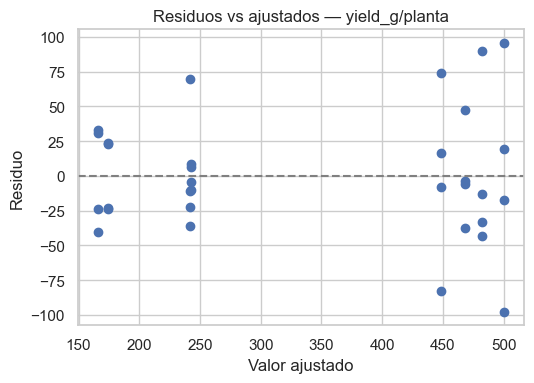

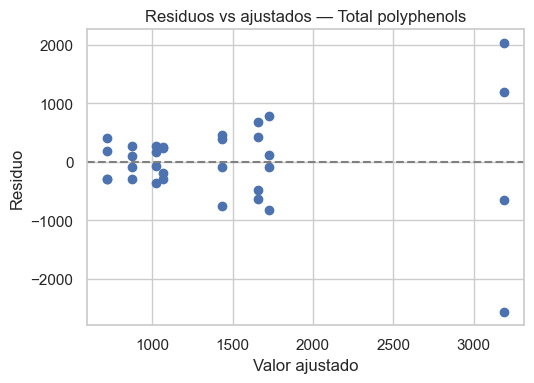

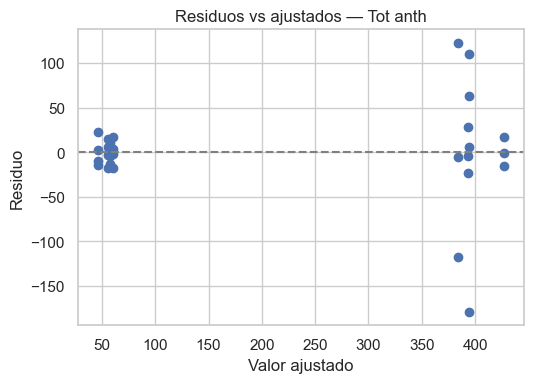

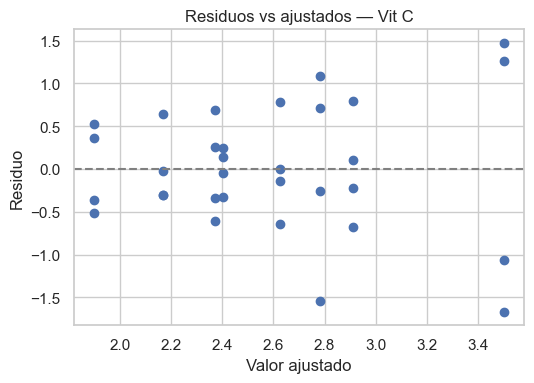

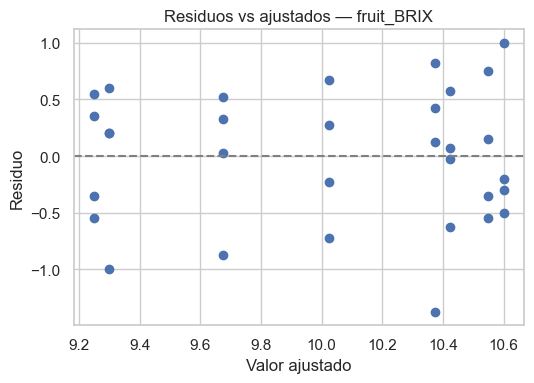

,Outcome,Shapiro_residuos_p,Levene_tratamientos_p
0,yield_g/planta,0.3508,0.3605
1,Total polyphenols,0.0051,0.1346
2,Tot anth,0.0000,0.9926
3,Vit C,0.7821,0.2995
4,fruit_BRIX,0.7081,0.8836


In [32]:
# Diagnóstico de supuestos para outcomes prioritarios.
assumption_rows=[]
PRIMARY_TARGETS=['yield_g/planta','Total polyphenols','Tot anth','Vit C','fruit_BRIX']
for col in [c for c in PRIMARY_TARGETS if c in work.columns]:
    d=work[['Treatment_name','Cultivar',col]].dropna().copy()
    fit=smf.ols(f'Q("{col}") ~ C(Treatment_name) * C(Cultivar)',data=d).fit()
    resid=fit.resid
    p_shapiro=shapiro(resid).pvalue if len(resid)<=5000 else np.nan
    groups=[g[col].to_numpy() for _,g in d.groupby('Treatment_name') if len(g)>=2]
    p_levene=levene(*groups,center='median').pvalue if len(groups)>=2 else np.nan
    assumption_rows.append({'Outcome':col,'Shapiro_residuos_p':p_shapiro,'Levene_tratamientos_p':p_levene})

    fig,ax=plt.subplots(figsize=(5.5,4))
    ax.scatter(fit.fittedvalues,resid)
    ax.axhline(0,linestyle='--',color='gray')
    ax.set_title(f'Residuos vs ajustados — {col}')
    ax.set_xlabel('Valor ajustado'); ax.set_ylabel('Residuo')
    plt.tight_layout(); plt.show()

display(pd.DataFrame(assumption_rows).round(4))


## 6.2 Modelos lineales mixtos (LMM)

Los LMM se utilizan como complemento del ANOVA para reconocer la estructura de bloques/réplicas.

Modelo conceptual:

`Outcome ~ Treatment * Cultivar + (1 | Block)`

Se utilizará `Replicate` como aproximación al bloque experimental y se mostrará también una sensibilidad con `Parcel_ID` cuando el ajuste sea viable. Debido al tamaño de muestra, una varianza aleatoria cercana a cero se interpretará como señal de que el componente aleatorio no está siendo identificado con precisión, no como evidencia de ausencia definitiva de variación de bloque.


In [33]:
# LMM en outcomes prioritarios. Powell se usa como optimizador robusto ante singularidad con n pequeño.
lmm_rows=[]
for col in [c for c in PRIMARY_TARGETS if c in work.columns]:
    d=work[['Treatment_name','Cultivar','Replicate','Parcel_ID',col]].dropna().copy()
    for grouping in ['Replicate','Parcel_ID']:
        try:
            with warnings.catch_warnings(record=True) as ws:
                warnings.simplefilter('always')
                fit=smf.mixedlm(f'Q("{col}") ~ C(Treatment_name) * C(Cultivar)',
                                 data=d,groups=d[grouping]).fit(reml=False,method='powell',maxiter=1000,disp=False)
            re_var=float(fit.cov_re.iloc[0,0]) if fit.cov_re.size else np.nan
            lmm_rows.append({'Outcome':col,'Agrupación':grouping,'Converged':fit.converged,
                             'AIC':fit.aic,'Random_intercept_var':re_var,
                             'Advertencias':' | '.join(str(w.message) for w in ws[:2])})
        except Exception as e:
            lmm_rows.append({'Outcome':col,'Agrupación':grouping,'Converged':False,
                             'AIC':np.nan,'Random_intercept_var':np.nan,'Advertencias':str(e)})

lmm_summary=pd.DataFrame(lmm_rows)
display(lmm_summary.round(4))


,Outcome,Agrupación,Converged,AIC,Random_intercept_var,Advertencias
0,yield_g/planta,Replicate,True,349.8671,344.3669,
1,yield_g/planta,Parcel_ID,True,351.7524,318.2979,
2,Total polyphenols,Replicate,True,531.6124,66669.7899,
3,Total polyphenols,Parcel_ID,True,531.8847,128161.1254,
4,Tot anth,Replicate,True,332.4319,0.0000,The MLE may be on the boundary of the paramete...
5,Tot anth,Parcel_ID,True,332.4319,0.0000,The MLE may be on the boundary of the paramete...
6,Vit C,Replicate,True,89.9059,0.0000,The MLE may be on the boundary of the paramete...
7,Vit C,Parcel_ID,True,89.6699,0.0630,
8,fruit_BRIX,Replicate,True,66.2392,0.1282,
9,fruit_BRIX,Parcel_ID,True,73.8371,0.0841,


## 6.3 Propiedades del suelo y cambios 2022 → 2023

El suelo se analiza a nivel de parcela, no duplicando Donna y Dream. Se revisan diferencias entre sistemas de manejo y el cambio temporal disponible.


In [34]:
# Comparación de suelo por tratamiento en 2023: ANOVA si varianzas son razonables; Kruskal como alternativa robusta.
soil_test_rows=[]
soil23_analysis=soil_time[soil_time['Year'].eq(2023)].copy()
soil_numeric=[c for c in soil_raw.columns if c not in ['Treatment','Year','Block','Plot'] and pd.api.types.is_numeric_dtype(soil_raw[c])]

for col in soil_numeric:
    groups=[g[col].dropna().to_numpy() for _,g in soil23_analysis.groupby('Treatment_name')]
    groups=[g for g in groups if len(g)>=3]
    if len(groups)<3: continue
    p_lev=levene(*groups,center='median').pvalue
    # Con n=4 por grupo la normalidad tiene poca potencia; registramos ambos contrastes y seleccionamos de forma conservadora.
    p_anova=f_oneway(*groups).pvalue
    p_kw=kruskal(*groups).pvalue
    method='ANOVA' if p_lev>=.05 else 'Kruskal-Wallis'
    p_selected=p_anova if method=='ANOVA' else p_kw
    soil_test_rows.append({'Variable':col,'Levene_p':p_lev,'ANOVA_p':p_anova,'Kruskal_p':p_kw,'Método_seleccionado':method,'p_seleccionado':p_selected})

soil_tests=pd.DataFrame(soil_test_rows)
if not soil_tests.empty:
    soil_tests['q_FDR']=multipletests(soil_tests['p_seleccionado'],method='fdr_bh')[1]
    display(soil_tests.sort_values('q_FDR').round(5))


,Variable,Levene_p,ANOVA_p,Kruskal_p,Método_seleccionado,p_seleccionado,q_FDR
1,C org,0.06889,0.07964,0.26466,ANOVA,0.07964,0.37257
8,Respiracion_microb (ug C-CO2/gsuelo·dia),0.20118,0.03563,0.06509,ANOVA,0.03563,0.37257
10,N_mineral_incubado,0.12963,0.10161,0.14447,ANOVA,0.10161,0.37257
0,Densidad ap,0.00008,0.34258,0.32556,Kruskal-Wallis,0.32556,0.57824
4,Microbial_biomass_C_sinincubar,0.35976,0.23815,0.17288,ANOVA,0.23815,0.57824
5,Microbial_biomass_C_incubado,0.09669,0.29881,0.30857,ANOVA,0.29881,0.57824
6,N_microbiano_sinincubar,0.17967,0.39688,0.45816,ANOVA,0.39688,0.57824
7,N_microbiano_incubado,0.01797,0.34352,0.42054,Kruskal-Wallis,0.42054,0.57824
3,C:N,0.19932,0.73572,0.49693,ANOVA,0.73572,0.80929
9,N _mineral _sinincubar,0.85994,0.68782,0.63726,ANOVA,0.68782,0.80929


## 6.4 RDA exploratoria: variación multivariada asociada con Treatment y Cultivar

La **Redundancy Analysis (RDA)** puede entenderse como una regresión multivariada seguida de una ordenación de la parte explicada. Aquí se implementa una versión exploratoria en Python para cuantificar cuánto del bloque de outcomes puede asociarse con Treatment y Cultivar.

Por el tamaño de muestra se utilizan **efectos principales** como restricciones; la interacción se estudia con ANOVA/LMM para evitar una RDA excesivamente parametrizada.


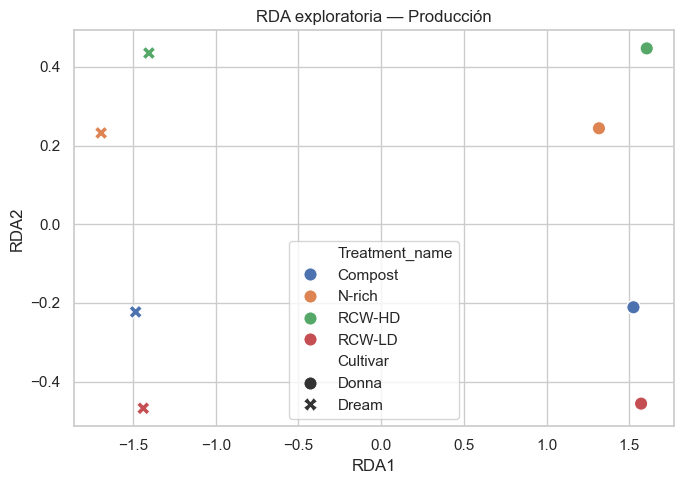

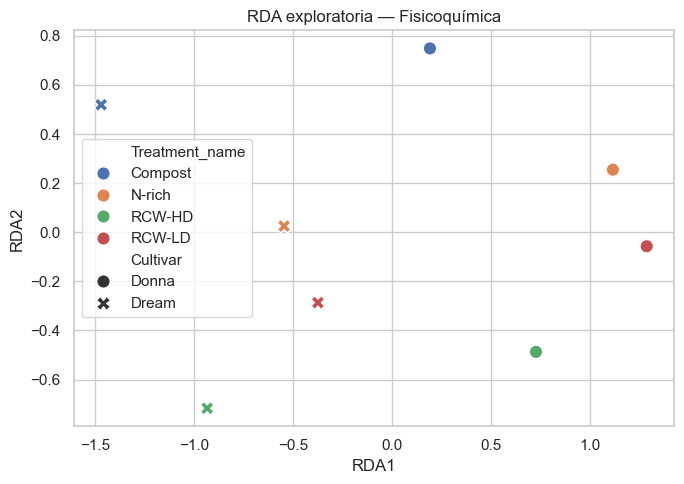

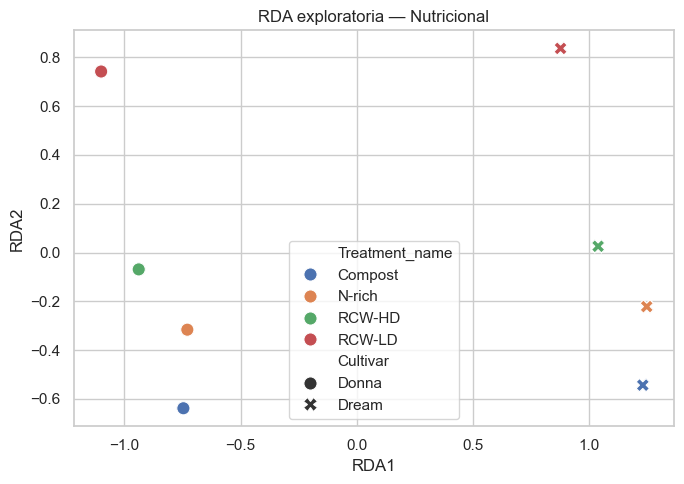

,Bloque,n,Variables Y,R2 multivariado,p permutación
0,Producción,32,4,0.6076,0.005
1,Fisicoquímica,32,5,0.2262,0.015
2,Nutricional,29,3,0.4173,0.005


In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RDA_BLOCKS={
    'Producción':[c for c in production_cols if c in work.columns],
    'Fisicoquímica':[c for c in ['fruit_Weight','fruit_Firm','fruit_BRIX','fruit_Acidity','fruit_Hydrat'] if c in work.columns],
    'Nutricional':[c for c in ['Total polyphenols','Tot anth','Vit C'] if c in work.columns],
}

def run_rda(df, ycols, label, n_perm=199):
    cols=['Treatment_name','Cultivar']+ycols
    d=df[cols].dropna().copy()
    if len(d)<16 or len(ycols)<2:
        return None
    X=pd.get_dummies(d[['Treatment_name','Cultivar']],drop_first=True,dtype=float)
    Y=StandardScaler().fit_transform(d[ycols])
    reg=LinearRegression().fit(X,Y)
    Yhat=reg.predict(X)
    sse=np.sum((Y-Yhat)**2); sst=np.sum(Y**2)
    r2=1-sse/sst
    rng=np.random.default_rng(SEED)
    perm=[]
    for _ in range(n_perm):
        Yp=Y[rng.permutation(len(Y))]
        Yhp=LinearRegression().fit(X,Yp).predict(X)
        perm.append(1-np.sum((Yp-Yhp)**2)/np.sum(Yp**2))
    p_perm=(1+np.sum(np.asarray(perm)>=r2))/(n_perm+1)
    ncomp=min(2,Yhat.shape[1],len(d)-1)
    ord=PCA(n_components=ncomp).fit_transform(Yhat)
    scores=pd.DataFrame(ord,index=d.index,columns=[f'RDA{i+1}' for i in range(ncomp)])
    scores=scores.join(d[['Treatment_name','Cultivar']])
    return {'label':label,'n':len(d),'vars':len(ycols),'r2':r2,'p_perm':p_perm,'scores':scores}

rda_results=[]
for label,cols in RDA_BLOCKS.items():
    res=run_rda(work,cols,label)
    if res:
        rda_results.append(res)
        s=res['scores']
        if {'RDA1','RDA2'}.issubset(s.columns):
            fig,ax=plt.subplots(figsize=(7,5))
            sns.scatterplot(data=s,x='RDA1',y='RDA2',hue='Treatment_name',hue_order=TREATMENT_ORDER,
                            style='Cultivar',s=90,ax=ax)
            ax.set_title(f'RDA exploratoria — {label}')
            plt.tight_layout(); plt.show()

rda_summary=pd.DataFrame([{'Bloque':r['label'],'n':r['n'],'Variables Y':r['vars'],'R2 multivariado':r['r2'],'p permutación':r['p_perm']} for r in rda_results])
display(rda_summary.round(4))


## 6.5 Modelos predictivos comparativos

Los modelos se comparan con **GroupKFold por parcela** sobre el conjunto de entrenamiento. El holdout permanece separado para una verificación final.

Modelos:

- DummyRegressor.
- Ridge.
- Elastic Net.
- PLS Regression.
- PCA + Ridge.
- Random Forest conservador.

Con `n≈32`, el objetivo no es maximizar décimas de R² mediante tuning agresivo, sino identificar qué familias de modelos agregan señal de forma reproducible.


In [36]:
from sklearn.linear_model import ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

MODELS={
    'Dummy (media)':DummyRegressor(strategy='mean'),
    'Ridge':Ridge(alpha=10.0),
    'Elastic Net':ElasticNet(alpha=.10,l1_ratio=.50,max_iter=20000,random_state=SEED),
    'PLS (2 comp.)':PLSRegression(n_components=2,scale=False,max_iter=500),
    'PCA 85% + Ridge':Pipeline([
        ('pca',PCA(n_components=.85,svd_solver='full')),
        ('ridge',Ridge(alpha=10.0))
    ]),
    'Random Forest':RandomForestRegressor(
        n_estimators=100,max_depth=3,min_samples_leaf=2,max_features='sqrt',
        random_state=SEED,n_jobs=1
    )
}

model_rows=[]
for label,col in MODEL_TARGETS.items():
    for model_name,model in MODELS.items():
        row=evaluate_model(model_name,model,label,col)
        if row: model_rows.append(row)

model_results=pd.DataFrame(model_rows)
dummy_lookup=model_results[model_results.Modelo=='Dummy (media)'].set_index('Objetivo')['CV_MAE']
model_results['Mejora_vs_Dummy_%']=model_results.apply(
    lambda r:100*(dummy_lookup.get(r['Objetivo'],np.nan)-r['CV_MAE'])/dummy_lookup.get(r['Objetivo'],np.nan),axis=1)
model_results['Cumple_minimo']=(model_results['Mejora_vs_Dummy_%']>=10)&(model_results['CV_R2']>0)&(model_results['Modelo']!='Dummy (media)')
model_results['Diagnostico_ajuste']=np.select(
    [model_results['Overfit_ratio_CV_vs_train']>1.75,
     (model_results['CV_R2']<=0)&(model_results['Modelo']!='Dummy (media)')],
    ['Posible sobreajuste','Señal predictiva débil'],default='Sin señal severa de sobreajuste'
)

leaderboard=(model_results.sort_values(['Objetivo','CV_MAE'])
             [['Objetivo','Modelo','Train_MAE','CV_MAE','CV_MAE_sd','CV_RMSE','CV_R2','Holdout_MAE','Holdout_R2','Mejora_vs_Dummy_%','Cumple_minimo','Diagnostico_ajuste']])
display(leaderboard.round(3))


,Objetivo,Modelo,Train_MAE,CV_MAE,CV_MAE_sd,CV_RMSE,CV_R2,Holdout_MAE,Holdout_R2,Mejora_vs_Dummy_%,Cumple_minimo,Diagnostico_ajuste
19,Acidez,Ridge,0.013,0.045,0.012,0.052,-0.026,0.062,-1.887,6.467,False,Posible sobreajuste
23,Acidez,Random Forest,0.024,0.045,0.014,0.054,-0.003,0.033,-0.113,6.447,False,Posible sobreajuste
21,Acidez,PLS (2 comp.),0.023,0.048,0.010,0.055,-0.274,0.055,-1.452,0.159,False,Posible sobreajuste
18,Acidez,Dummy (media),0.047,0.048,0.015,0.059,-0.134,0.032,-0.174,0.000,False,Sin señal severa de sobreajuste
20,Acidez,Elastic Net,0.047,0.048,0.015,0.059,-0.134,0.032,-0.174,0.000,False,Señal predictiva débil
22,Acidez,PCA 85% + Ridge,0.034,0.048,0.019,0.056,-0.019,0.043,-0.631,-1.445,False,Señal predictiva débil
34,Antocianinas totales,PCA 85% + Ridge,41.724,59.487,9.400,74.496,0.786,96.938,0.586,62.899,True,Sin señal severa de sobreajuste
35,Antocianinas totales,Random Forest,31.264,65.913,7.911,79.287,0.763,107.756,0.551,58.891,True,Posible sobreajuste
33,Antocianinas totales,PLS (2 comp.),25.567,70.533,11.480,84.013,0.716,86.856,0.663,56.009,True,Posible sobreajuste
31,Antocianinas totales,Ridge,14.253,74.400,10.579,89.798,0.686,75.463,0.750,53.598,True,Posible sobreajuste


,Objetivo,Modelo,CV_MAE,CV_RMSE,CV_R2,Holdout_MAE,Holdout_R2,Mejora_vs_Dummy_%,Cumple_minimo,Diagnostico_ajuste
0,Acidez,Ridge,0.045,0.052,-0.026,0.062,-1.887,6.467,False,Posible sobreajuste
1,BRIX,PCA 85% + Ridge,0.546,0.660,-0.026,0.608,0.312,8.558,False,Señal predictiva débil
2,Producción comercial Ton/ha,Ridge,0.646,0.765,0.905,1.501,0.474,72.797,True,Posible sobreajuste
3,Vitamina C,Random Forest,0.648,0.855,-0.442,0.664,-0.511,5.774,False,Posible sobreajuste
4,Rendimiento g/planta,Elastic Net,41.987,48.859,0.887,81.990,0.284,69.452,True,Posible sobreajuste
5,Antocianinas totales,PCA 85% + Ridge,59.487,74.496,0.786,96.938,0.586,62.899,True,Sin señal severa de sobreajuste
6,Polifenoles totales,Random Forest,609.553,815.921,-0.699,1130.854,-0.178,-5.072,False,Posible sobreajuste


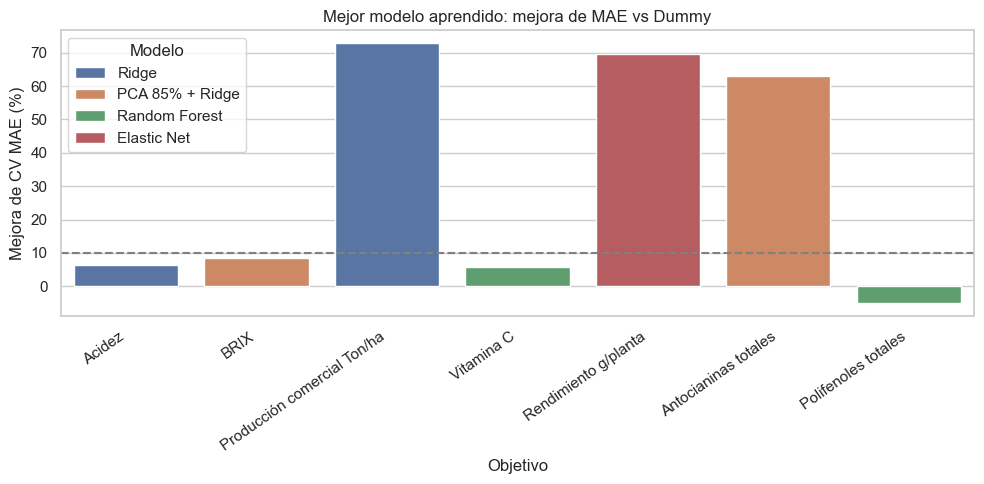

In [37]:
# Mejor modelo por objetivo según CV MAE, excluyendo Dummy para identificar la mejor solución aprendida.
learned=model_results[model_results['Modelo']!='Dummy (media)'].copy()
best_idx=learned.groupby('Objetivo')['CV_MAE'].idxmin()
best_models=learned.loc[best_idx].sort_values('CV_MAE').reset_index(drop=True)
display(best_models[['Objetivo','Modelo','CV_MAE','CV_RMSE','CV_R2','Holdout_MAE','Holdout_R2','Mejora_vs_Dummy_%','Cumple_minimo','Diagnostico_ajuste']].round(3))

fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=best_models,x='Objetivo',y='Mejora_vs_Dummy_%',hue='Modelo',dodge=False,ax=ax)
ax.axhline(10,linestyle='--',color='gray',label='Mínimo 10%')
ax.set_title('Mejor modelo aprendido: mejora de MAE vs Dummy')
ax.set_ylabel('Mejora de CV MAE (%)'); ax.set_xlabel('Objetivo')
plt.xticks(rotation=35,ha='right'); plt.tight_layout(); plt.show()


## 6.6 Subajuste / sobreajuste

Se compara el MAE de entrenamiento contra el MAE de validación cruzada.

- **Train muy bajo + CV mucho mayor:** señal de posible sobreajuste.
- **Train y CV ambos altos:** posible subajuste o información insuficiente.
- **Train y CV cercanos y mejores que Dummy:** señal más saludable.

Con una muestra tan pequeña, estas señales son diagnósticas, no pruebas definitivas.


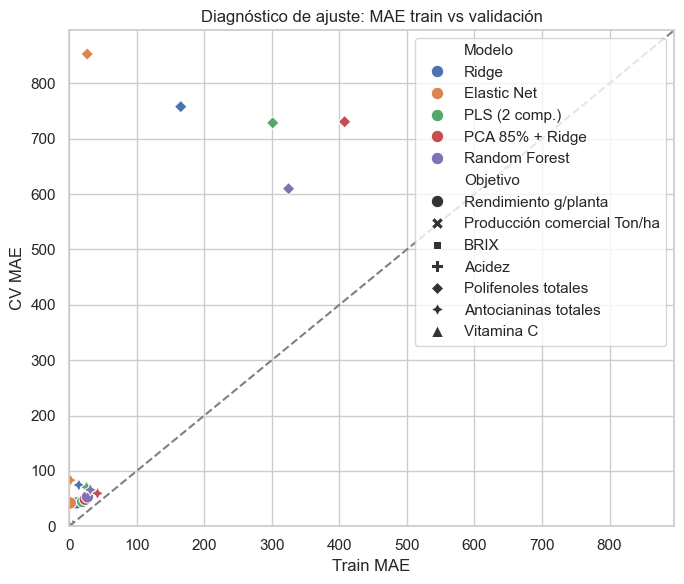

In [38]:
# Visualización train vs CV para todos los modelos aprendidos.
plot_fit=learned.copy()
fig,ax=plt.subplots(figsize=(7,6))
sns.scatterplot(data=plot_fit,x='Train_MAE',y='CV_MAE',hue='Modelo',style='Objetivo',s=80,ax=ax)
lims=[0,max(plot_fit['Train_MAE'].max(),plot_fit['CV_MAE'].max())*1.05]
ax.plot(lims,lims,linestyle='--',color='gray')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title('Diagnóstico de ajuste: MAE train vs validación')
ax.set_xlabel('Train MAE'); ax.set_ylabel('CV MAE')
plt.tight_layout(); plt.show()


## 6.7 Importancia de características

Se usarán dos lecturas complementarias:

- **Coeficientes absolutos de Ridge:** como `X` está estandarizada, permiten comparar magnitudes relativas.
- **Permutation Importance de Random Forest:** mide cuánto empeora el desempeño cuando una característica se desordena.

La importancia predictiva **no implica causalidad**.


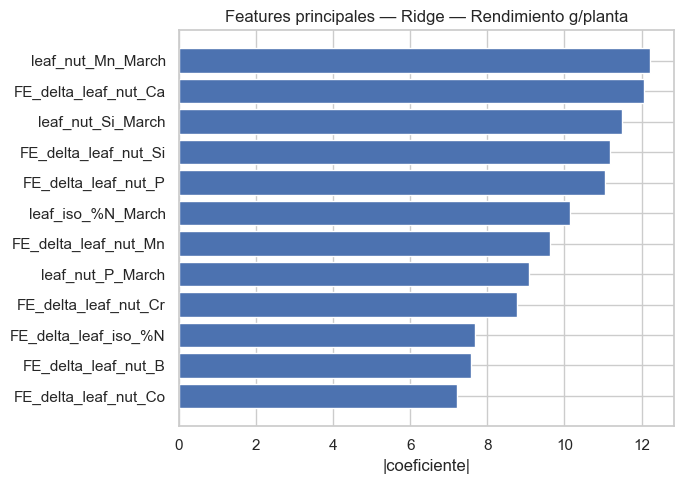

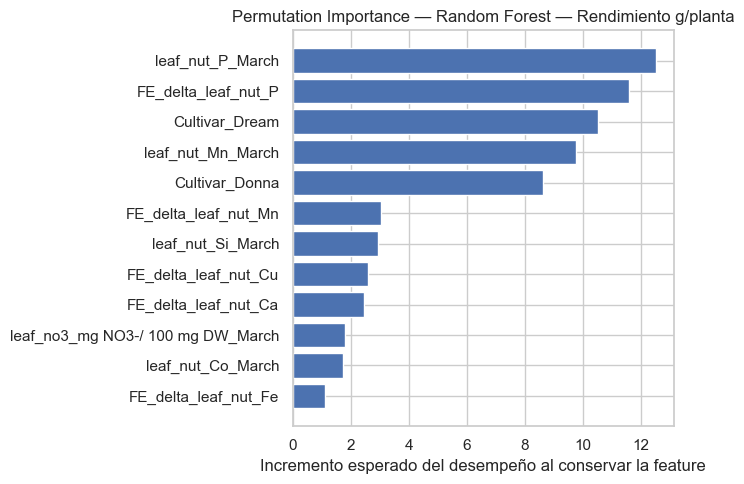

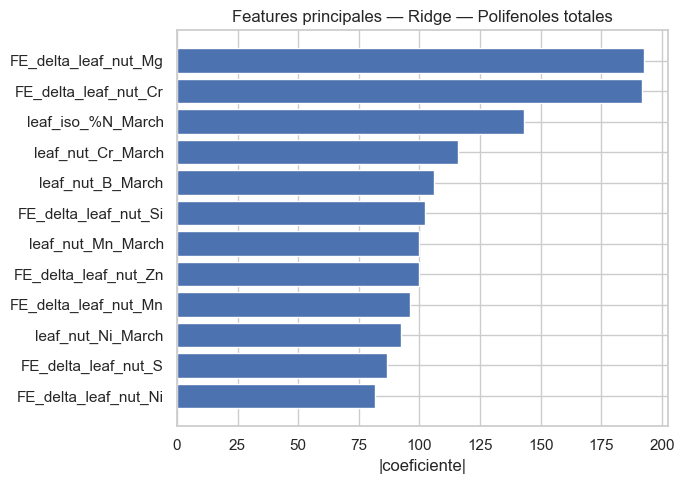

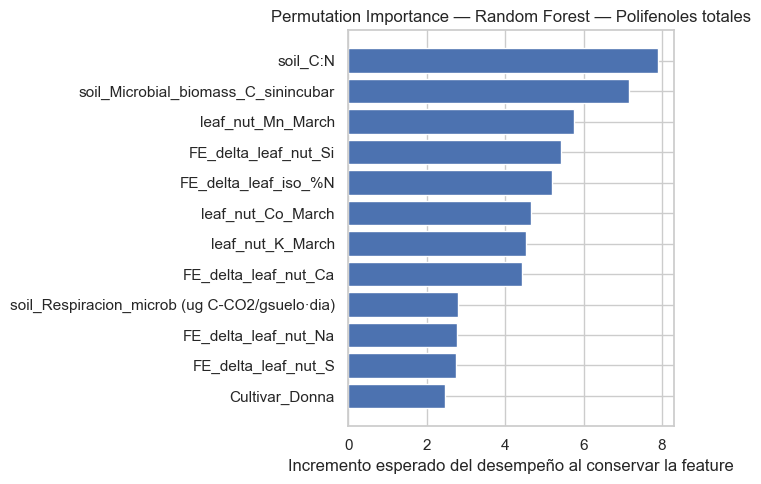

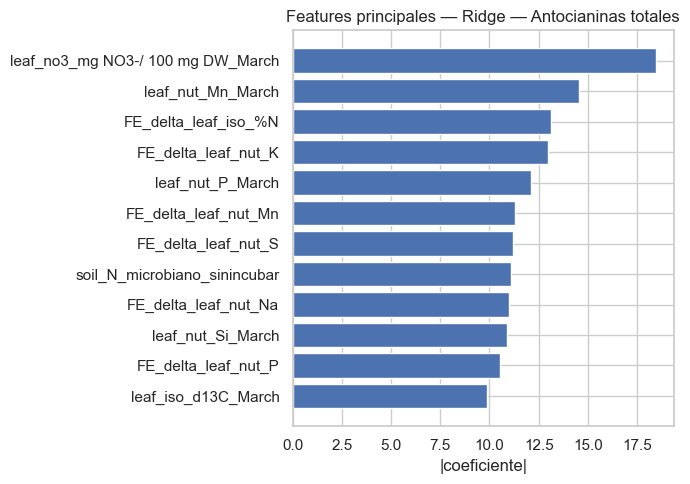

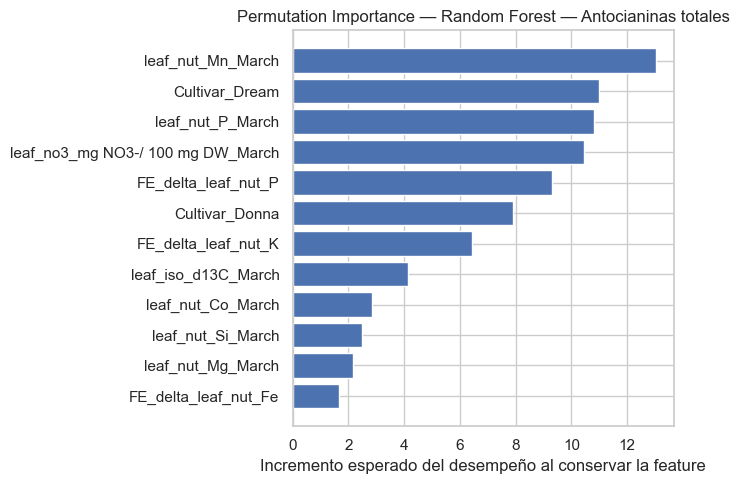

In [39]:
from sklearn.inspection import permutation_importance

importance_tables=[]
IMPORTANCE_TARGETS=[c for c in ['yield_g/planta','Total polyphenols','Tot anth'] if c in work.columns]
for target_col in IMPORTANCE_TARGETS:
    target_label=next((k for k,v in MODEL_TARGETS.items() if v==target_col),target_col)
    mtr=tr[target_col].notna(); mte=te[target_col].notna()
    X_train=Xtr_depurado.loc[mtr]; y_train=tr.loc[mtr,target_col].astype(float)
    X_test=Xte_depurado.loc[mte]; y_test=te.loc[mte,target_col].astype(float)

    # Ridge coefficients.
    ridge=Ridge(alpha=10.0).fit(X_train,y_train)
    imp=pd.DataFrame({'Feature':X_train.columns,'Importancia':np.abs(ridge.coef_),'Método':'|Coeficiente Ridge|','Objetivo':target_label})
    importance_tables.append(imp)
    top=imp.sort_values('Importancia',ascending=False).head(12).sort_values('Importancia')
    fig,ax=plt.subplots(figsize=(7,5))
    ax.barh(top['Feature'],top['Importancia'])
    ax.set_title(f'Features principales — Ridge — {target_label}')
    ax.set_xlabel('|coeficiente|')
    plt.tight_layout(); plt.show()

    # Permutation importance de RF sobre holdout, si hay suficiente información.
    if len(y_test)>=5 and y_test.nunique()>=2:
        rf=RandomForestRegressor(n_estimators=120,max_depth=3,min_samples_leaf=2,max_features='sqrt',random_state=SEED,n_jobs=1)
        rf.fit(X_train,y_train)
        pi=permutation_importance(rf,X_test,y_test,n_repeats=8,random_state=SEED,scoring='neg_mean_absolute_error',n_jobs=-1)
        imp2=pd.DataFrame({'Feature':X_train.columns,'Importancia':pi.importances_mean,'Método':'Permutation RF','Objetivo':target_label})
        importance_tables.append(imp2)
        top2=imp2.sort_values('Importancia',ascending=False).head(12).sort_values('Importancia')
        fig,ax=plt.subplots(figsize=(7,5))
        ax.barh(top2['Feature'],top2['Importancia'])
        ax.set_title(f'Permutation Importance — Random Forest — {target_label}')
        ax.set_xlabel('Incremento esperado del desempeño al conservar la feature')
        plt.tight_layout(); plt.show()

feature_importance=pd.concat(importance_tables,ignore_index=True) if importance_tables else pd.DataFrame()


## 6.8 PLS como puente entre explicación y predicción

PLS es especialmente relevante en este estudio porque crea componentes que maximizan la covariación entre `X` (suelo/hoja/RGB) y cada outcome. A diferencia de PCA, sus componentes sí están orientados hacia `Y`.

Para mantener interpretabilidad mostraremos los pesos absolutos del PLS en outcomes prioritarios.


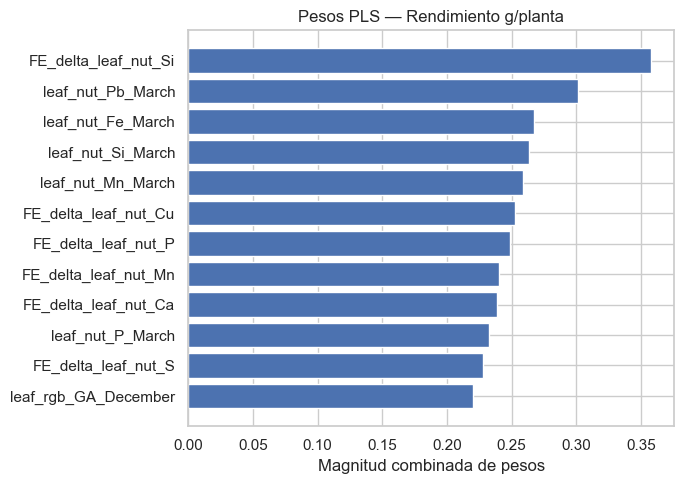

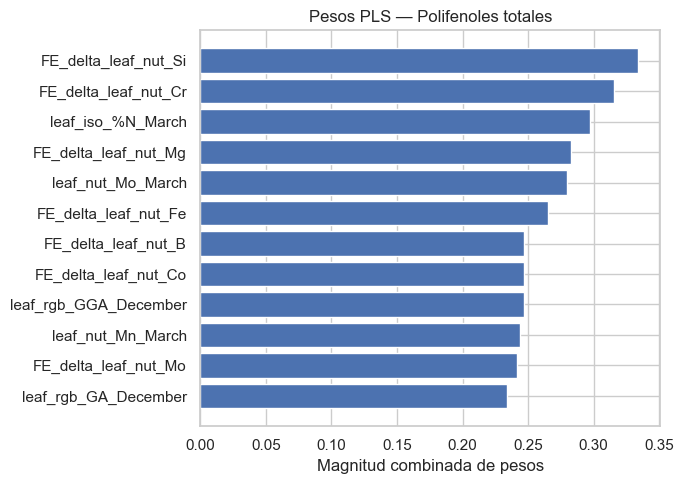

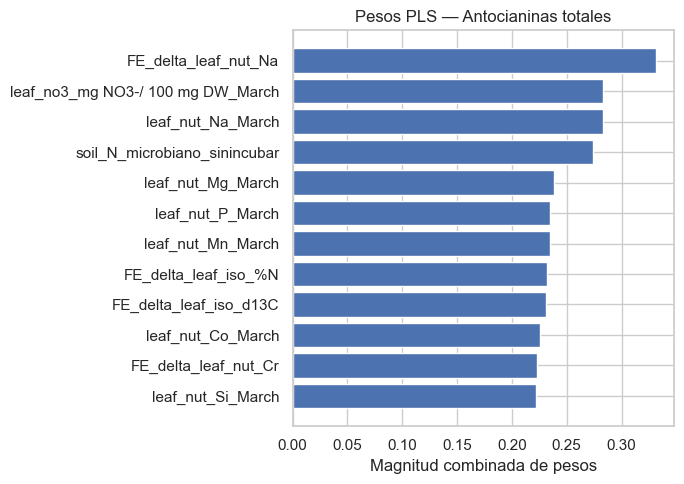

In [40]:
# Pesos PLS para outcomes prioritarios.
pls_weight_tables=[]
for target_col in IMPORTANCE_TARGETS:
    target_label=next((k for k,v in MODEL_TARGETS.items() if v==target_col),target_col)
    mtr=tr[target_col].notna()
    X_train=Xtr_depurado.loc[mtr]; y_train=tr.loc[mtr,target_col].astype(float)
    if len(y_train)<12: continue
    ncomp=min(2,X_train.shape[1],len(y_train)-1)
    pls=PLSRegression(n_components=ncomp,scale=False,max_iter=500).fit(X_train,y_train)
    weights=np.sqrt((pls.x_weights_**2).sum(axis=1))
    tbl=pd.DataFrame({'Feature':X_train.columns,'PLS_weight':weights,'Objetivo':target_label})
    pls_weight_tables.append(tbl)
    top=tbl.sort_values('PLS_weight',ascending=False).head(12).sort_values('PLS_weight')
    fig,ax=plt.subplots(figsize=(7,5))
    ax.barh(top['Feature'],top['PLS_weight'])
    ax.set_title(f'Pesos PLS — {target_label}')
    ax.set_xlabel('Magnitud combinada de pesos')
    plt.tight_layout(); plt.show()

pls_weights=pd.concat(pls_weight_tables,ignore_index=True) if pls_weight_tables else pd.DataFrame()


# 7. Comparación de resultados y conclusiones

### ¿Qué haremos?
Integraremos resultados estadísticos, multivariados y predictivos sin forzar una única definición de “mejor tratamiento”.

### ¿Por qué?
Un tratamiento puede favorecer producción y otro favorecer compuestos bioactivos. El proyecto es inherentemente **multiobjetivo**.

### ¿Qué esperamos obtener?
Una lectura de viabilidad: qué preguntas ya pueden responderse con estos datos, qué modelos agregan valor y qué limitaciones deben conservarse para la siguiente fase.


In [41]:
# Tabla final de viabilidad por objetivo.
final_viability=best_models[['Objetivo','Modelo','CV_MAE','CV_R2','Holdout_MAE','Holdout_R2','Mejora_vs_Dummy_%','Cumple_minimo']].copy()
final_viability['Estado']=np.where(final_viability['Cumple_minimo'],'Viable vs baseline','Aún no supera criterio mínimo')
display(final_viability.round(3))

# Frecuencia de modelos ganadores.
model_wins=best_models['Modelo'].value_counts().rename_axis('Modelo').reset_index(name='Objetivos donde fue mejor')
display(model_wins)


,Objetivo,Modelo,CV_MAE,CV_R2,Holdout_MAE,Holdout_R2,Mejora_vs_Dummy_%,Cumple_minimo,Estado
0,Acidez,Ridge,0.045,-0.026,0.062,-1.887,6.467,False,Aún no supera criterio mínimo
1,BRIX,PCA 85% + Ridge,0.546,-0.026,0.608,0.312,8.558,False,Aún no supera criterio mínimo
2,Producción comercial Ton/ha,Ridge,0.646,0.905,1.501,0.474,72.797,True,Viable vs baseline
3,Vitamina C,Random Forest,0.648,-0.442,0.664,-0.511,5.774,False,Aún no supera criterio mínimo
4,Rendimiento g/planta,Elastic Net,41.987,0.887,81.990,0.284,69.452,True,Viable vs baseline
5,Antocianinas totales,PCA 85% + Ridge,59.487,0.786,96.938,0.586,62.899,True,Viable vs baseline
6,Polifenoles totales,Random Forest,609.553,-0.699,1130.854,-0.178,-5.072,False,Aún no supera criterio mínimo


,Modelo,Objetivos donde fue mejor
0,Ridge,2
1,PCA 85% + Ridge,2
2,Random Forest,2
3,Elastic Net,1


# Conclusiones dinámicas basadas en resultados realmente calculados.
viable=int(final_viability['Cumple_minimo'].sum())
total=len(final_viability)
sig_anova=anova_results[anova_results['q_FDR']<.05] if not anova_results.empty else pd.DataFrame()
sig_corr=corr_results[corr_results['q_FDR']<.05] if not corr_results.empty else pd.DataFrame()

best_text='; '.join([f"{r.Objetivo}: {r.Modelo}" for r in best_models.itertuples()])

conclusions=f"""
## Conclusiones del Avance 3

1. **Estructura experimental.** Se trabajó con **{len(work)} observaciones analíticas** y **{work.Parcel_ID.nunique()} parcelas**, separando train/test por `Parcel_ID` para reducir fuga de información asociada con suelo compartido.

2. **Tratamientos visibles.** En tablas y gráficos se presentan **Compost, N-rich, RCW-HD y RCW-LD** en lugar de T1-T4. Los códigos se conservan únicamente como llave técnica.

3. **Outliers.** Se identificaron **{len(outlier_registry)} casos variable-observación** mediante IQR. No se eliminaron automáticamente porque pueden corresponder a respuestas experimentales de interés.

4. **Preprocesamiento.** Se generaron **{len(derived)} características temporales**, se aplicó Yeo-Johnson a **{len(transformers)} variables** con asimetría elevada y los predictores numéricos se redujeron de **{len(num_cols)}** a **{len(selected_corr)}** después de controlar varianza, duplicados y correlación extrema.

5. **Inferencia experimental.** Los ANOVA con corrección FDR identificaron **{len(sig_anova)} efectos** con `q < 0.05` entre Treatment, Cultivar o su interacción. Estos resultados deben leerse junto con diagnósticos y LMM, no como causalidad automática.

6. **Relaciones entre bloques.** Se evaluaron **{len(corr_results)} asociaciones Spearman** estratificadas por cultivar; **{len(sig_corr)}** sobrevivieron `q_FDR < 0.05`. La prioridad interpretativa es nutrición mineral → calidad del fruto.

7. **Baseline predictivo.** **{viable} de {total} objetivos** superaron el criterio mínimo definido (≥10% de mejora de MAE vs Dummy y `CV R² > 0`) con al menos un modelo aprendido.

8. **Modelos ganadores por objetivo.** {best_text}.

9. **Interpretabilidad.** Ridge, PLS y Permutation Importance permiten estudiar qué variables sostienen la señal predictiva. Estas importancias describen capacidad predictiva y no deben traducirse directamente a mecanismos causales.

10. **Limitación central.** El tamaño muestral es pequeño (`n≈32`) y `Treatment` representa un sistema de manejo que combina enmienda y práctica de labranza. Los resultados sirven para comparar las condiciones observadas, pero no para aislar de forma causal el efecto independiente de la labranza ni para extrapolar a tratamientos no estudiados.

### Decisión para la siguiente fase

El siguiente paso debe concentrarse en los outcomes que sí superan el baseline, validar estabilidad de las features importantes y construir una lectura multiobjetivo que contraste **producción, calidad fisicoquímica y calidad nutricional**, en lugar de elegir una única “mejor fresa” a partir de una sola métrica.
"""
display(Markdown(conclusions))


## 7.1 Lectura de sub/sobreajuste

Para la entrega, la conclusión sobre ajuste debe apoyarse en tres señales:

1. Diferencia `Train_MAE` vs `CV_MAE`.
2. Comportamiento en holdout.
3. Variabilidad entre folds (`CV_MAE_sd`).

Un modelo con train casi perfecto y CV/holdout claramente peores se considera candidato a sobreajuste. Con tan pocas observaciones, no se seleccionará un modelo únicamente por el mejor valor puntual de holdout.


In [43]:
# Exportación de resultados principales para trazabilidad.
features_removed=pd.DataFrame(filter_log)
model_results.to_csv(OUT/'model_comparison.csv',index=False)
baseline_results.to_csv(OUT/'baseline_results.csv',index=False)
final_viability.to_csv(OUT/'model_viability.csv',index=False)
anova_results.to_csv(OUT/'anova_two_way_fdr.csv',index=False)
lmm_summary.to_csv(OUT/'mixed_models_summary.csv',index=False)
soil_tests.to_csv(OUT/'soil_tests_2023.csv',index=False)
corr_results.to_csv(OUT/'spearman_cross_blocks_fdr.csv',index=False)
outlier_registry.to_csv(OUT/'outlier_registry.csv',index=False)
features_removed.to_csv(OUT/'features_removed.csv',index=False)
transform_report.to_csv(OUT/'transformations.csv',index=False)
pd.DataFrame(pca_summary).to_csv(OUT/'pca_summary.csv',index=False)
rda_summary.to_csv(OUT/'rda_summary.csv',index=False)
if not feature_importance.empty:
    feature_importance.to_csv(OUT/'feature_importance.csv',index=False)
if not pls_weights.empty:
    pls_weights.to_csv(OUT/'pls_weights.csv',index=False)

print('Resultados exportados a:',OUT)
for p in sorted(OUT.glob('*.csv')):
    print(' -',p.name)


Resultados exportados a: C:\Users\joaqu\OneDrive\Documentos\02. Maestría Tec\8° Trimestre\Proyecto Integrador\outputs\avance3_modelado
 - anova_two_way_fdr.csv
 - baseline_results.csv
 - feature_importance.csv
 - features_removed.csv
 - mixed_models_summary.csv
 - model_comparison.csv
 - model_viability.csv
 - outlier_registry.csv
 - pca_summary.csv
 - pls_weights.csv
 - rda_summary.csv
 - soil_tests_2023.csv
 - spearman_cross_blocks_fdr.csv
 - transformations.csv


## 7.2 Checklist de rúbrica

| Criterio | Evidencia en la libreta |
|---|---|
| **Algoritmo** | Baseline Dummy + Ridge, justificación por tipo/cantidad de datos e interpretabilidad; comparación con Elastic Net, PLS, PCA+Ridge y RF |
| **Características importantes** | Correlación, filtros, PCA, coeficientes Ridge, PLS y Permutation Importance |
| **Sub/sobreajuste** | Train vs CV, GroupKFold, holdout, dispersión entre folds y residuos estadísticos |
| **Métrica** | MAE principal, RMSE y R² secundarios, todos justificados |
| **Desempeño** | Dummy como referencia y mínimo de 10% de mejora + CV R² > 0 |

### Nota metodológica

La validación cruzada de modelos se realiza después de un preprocesamiento **ajustado exclusivamente con el conjunto train del holdout**. Esto mantiene al conjunto de prueba completamente aislado. Con una muestra mayor sería preferible una validación anidada donde incluso la selección no supervisada se re-ajuste dentro de cada fold.


In [44]:
# Controles finales de calidad.
checks=pd.DataFrame([
    {'Control':'32 observaciones esperadas','Cumple':len(work)==32},
    {'Control':'16 parcelas esperadas','Cumple':work.Parcel_ID.nunique()==16},
    {'Control':'Nombres visibles de tratamiento','Cumple':set(work.Treatment_name.unique())==set(TREATMENT_ORDER)},
    {'Control':'Train/test sin overlap de parcela','Cumple':set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))},
    {'Control':'Outliers no eliminados automáticamente','Cumple':len(work)==len(ana_fe)},
    {'Control':'Baseline Dummy + Ridge ejecutado','Cumple':{'Dummy (media)','Ridge baseline'}.issubset(set(baseline_results.Modelo))},
    {'Control':'Múltiples familias de outcome','Cumple':len(MODEL_TARGETS)>=6},
    {'Control':'Modelos comparativos ejecutados','Cumple':model_results.Modelo.nunique()>=5},
    {'Control':'ANOVA factorial ejecutado','Cumple':len(anova_results)>0},
    {'Control':'Correlaciones con FDR ejecutadas','Cumple':len(corr_results)>0},
    {'Control':'PCA global ejecutado','Cumple':pca_global.n_components_>=2},
    {'Control':'RDA exploratoria ejecutada','Cumple':len(rda_results)>=2},
])
display(checks)
assert checks['Cumple'].all(), 'Algún control final no se cumplió.'
assert Xtr_depurado.columns.equals(Xte_depurado.columns)
assert Xtr_depurado.notna().all().all() and Xte_depurado.notna().all().all()
print('Avance3.Equipo54 listo para ejecución secuencial.')


,Control,Cumple
0,32 observaciones esperadas,True
1,16 parcelas esperadas,True
2,Nombres visibles de tratamiento,True
3,Train/test sin overlap de parcela,True
4,Outliers no eliminados automáticamente,True
5,Baseline Dummy + Ridge ejecutado,True
6,Múltiples familias de outcome,True
7,Modelos comparativos ejecutados,True
8,ANOVA factorial ejecutado,True
9,Correlaciones con FDR ejecutadas,True


Avance3.Equipo54 listo para ejecución secuencial.
